In [ ]:
import warnings
warnings.filterwarnings("ignore")

# Mô tả bài toán
**Bài toán**: Phân loại chủ đề bài báo dựa trên tiêu đề và nội dung

---
Gồm các thành viên:
* Nguyễn An Hưng
* Nguyễn Cửu Nhật Quang
* Nguyễn Đình Anh Tiến
---

**Lý do chọn đề tài**: Trong những năm gần đây, công nghệ 4.0 dần phát triển mạnh ở nước ta (Việt Nam), đơn cử là sự hiện diện của AI, những mô hình tự sinh như chatGPT, mô hình ngôn ngữ lớn,... đã và đang hỗ trợ cho chúng ta trong việc xử lý các bài toán về dữ liệu ngôn ngữ một cách thuận tiện. Tuy nhiên, để phân loại chúng theo các chủ đề vẫn là một bài toán quan trọng bởi đối với những phóng viên báo chí mong muốn tự động hóa quá trình gán chủ đề / nhãn cho bài viết của mình hay đối với đọc giả mong muốn tìm kiếm các bài viết theo chủ đề mong muốn.


**Mục đích đề tài**: Bài toán được xây dựng với mục đích gán chủ đề/ nhãn một cách tự động cho một bài viết đang thực hiện (real-time) bởi tác giả, hoặc xác định các chủ đề, các bài viết liên quan cho các bài báo chưa được gán chủ đề.


# 1. Crawl Data
Dữ liệu xử lý cho bài toán phân loại chủ đề bài báo. Với hai nguồn dữ liệu chính:
- Báo Dân trí ([dantri.com.vn](https://dantri.com.vn))
- Báo VNExpress ([vnexpress.net](https://vnexpress.net))

Với các chủ đề được sử dụng trong bài toán bao gồm (8 chủ đề):
* Thế giới
* Thể thao
* Giáo dục
* Pháp luật
* Sức khỏe
* Du lịch
* Đời sống
* Giải trí



## 1.1. Báo Dân trí ([dantri.com.vn](https://dantri.com.vn/))
Trong nguồn dữ liệu trang báo Dân trí. Nhóm sử dụng thư viện hỗ trợ crawl data chính là bs4 (Nếu chưa có mọi người có thể cài đặt thông qua câu lệnh `pip install beautifulsoup4`). Dữ liệu thu thập gồm các cột như sau:
* **time**: Thời gian bài báo được công bố (hoặc lần chỉnh sửa cuối cùng)
* **title**: Tiêu đề bài báo
* **description**: Mô tả/tóm tắt bài báo
* **content**: Nội dung bài báo
* **author**: Tên tác giả
* **author_link**: Đường dẫn tác giả
* **category**: Chủ đề bài báo
* **link**: Đường dẫn bài báo

Trong ngồn dữ liệu này, nhóm thu thập những dữ liệu bao gồm các nhãn (8 chủ đề):
* Thế giới
* Thể thao
* Giáo dục
* Pháp luật
* Sức khỏe
* Du lịch
* Đời sống
* Giải trí

In [ ]:
from bs4 import BeautifulSoup
import requests
import re
import pandas as pd


def getHTMLdocument(url):
    """
        getHTMLdocument(url) -> _type_
    Args:
        url (str): URL of the website

    Returns:
        str: HTML document of the website
    """
    response = requests.get(url)
    return response.text


class DanTriArticle:
    """
        DanTriArticle(url, OUT_DIR) -> _type_
    Args:
        url (str): URL of the website
        OUT_DIR (str): Output directory
    """
    def __init__(self, url, OUT_DIR):
        self.url = url
        self.OUT_DIR = OUT_DIR

    def get_categories(self, categories = ["Thế giới", "Thể thao", "Giáo dục", "Pháp luật", "Sức khỏe", "Du lịch", "Đời sống", "Giải trí"]):
        html_document = getHTMLdocument(self.url)
        soup = BeautifulSoup(html_document, 'html.parser')

        categories_link = []

        for x in soup.find_all('ol', {'class': 'nf-menu'})[0].find_all('li'):
            category = x.find('a').text.strip()
            if (category in categories):
                categories_link.append({"category": category, "link": x.find('a').get('href')})

        return categories_link

    def get_articles(self, category, page = 10):
        name = category['link'].split('.')[0].replace('/', '_')
        f = open(f"{self.OUT_DIR}/url{name}.txt", "w")

        for i in range(1, page + 1):
            sub_url = f"{self.url}{category['link'].split('.')[0]}/trang-{i}.htm"
            print(sub_url)
            soup = BeautifulSoup(getHTMLdocument(sub_url), 'html.parser')
            for e in soup.find_all("a", {'class': "dt-text-black-mine"}):
                f.write(f"{e.text.strip()}\t{e.get('href')}\n")
        f.close()

    def get_article(self, url):
        soup = BeautifulSoup(getHTMLdocument(f"{self.url}{url}"), 'html.parser')
        article = soup.find("article")
        if article is None:
            return None

        # print(f"link: {url}")

        # get article's content
        type_article = soup.find("div", {"class":"emagazine-category"})
        # print(f"Type article: {type_article}")
        if type_article is None:
            # Normal news
            time = article.find("time", {"class": "author-time"}).get("datetime")
            title = article.find("h1", {"class": "title-page detail"}).text.strip()
            description = article.find("h2", {"class": "singular-sapo"}).text.strip()
            content = article.find("div", {"class": "singular-content"}).text.strip()

            if article.find("div", {"class": "author-name"}) is None:
                author = ""
                author_link = ""
            else:
                author = article.find("div", {"class": "author-name"}).text.strip()
                author_link = article.find("div", {"class": "author-name"}).find("a").get("href")

            return {"title": title, "description": description, "content": content, "author": author, "author_link": author_link, "time": time}

        else:
            type_article = type_article.find("img").get("alt")
            if type_article == "DNews":
                # DNews
                time = article.find("time", {"class": "author-time"}).get("datetime")
                title = article.find("h1", {"class": "e-magazine__title"}).text.strip()
                description = article.find("h2", {"class": "e-magazine__sapo"}).text.strip()
                content = article.find("div", {"class": "e-magazine__body dnews__body"}).text.strip()

                if article.find("div", {"class": "author-name"}) is None:
                    author = ""
                    author_link = ""
                else:
                    author = article.find("div", {"class": "author-name"}).text.strip()
                    author_link = article.find("div", {"class": "author-name"}).find("a").get("href")

                return {"title": title, "description": description, "content": content, "author": author, "author_link": author_link, "time": time}

            elif type_article == "PhotoStory":
                # Photo story
                time = article.find("time", {"class": "e-magazine__meta-item"}).get("datetime")
                title = article.find("h1", {"class": "e-magazine__title"}).text.strip()
                description = article.find("h2", {"class": "e-magazine__sapo sapo-top"}).text.strip()
                content = article.find("div", {"class": "e-magazine__body"}).text.strip()

                if article.find("div", {"class": "e-magazine__meta"}) is None:
                    author = ""
                    author_link = ""
                else:
                    author = article.find("div", {"class": "e-magazine__meta"}).text.strip()
                    author_link = article.find("div", {"class": "e-magazine__meta"}).find("a").get("href")

                return {"title": title, "description": description, "content": content, "author": author, "author_link": author_link, "time": time}

In [ ]:
url_to_scrape = "https://dantri.com.vn"
OUT_DIR = "dantri"
dantri_article = DanTriArticle(url_to_scrape, OUT_DIR)

In [ ]:
categories = dantri_article.get_categories()

In [ ]:
import os
os.system("mkdir dantri")
# get articles and save the title and url to file for each category
for category in categories:
    dantri_article.get_articles(category)

In [ ]:
categories

In [ ]:
# read the data from the file
special_links = []
for c in categories:
    df_output = pd.DataFrame(columns=['time', 'title', 'description','content', 'author', 'author_link', 'category', 'link'])
    name = c["category"]
    data = pd.read_csv(f'{OUT_DIR}/url{c["link"].split(".")[0].replace("/", "_")}.txt', sep='\t', header=None)

    print(f"Category: {name}")
    for i in range(len(data)):
        _, link = data.iloc[i]

        try:
            article = dantri_article.get_article(link)
            df_output = df_output._append({"time": article["time"], "title": article["title"], "description": article["description"], "content": article["content"], "author": article["author"], "author_link": article["author_link"], "category": name, "link": link}, ignore_index=True)
        except Exception as e:
            special_links.append(link)
            print(f"Special link: {link}")
            print(f"e: {e}")

    df_output.to_csv(f"{OUT_DIR}/{c['link'].split('.')[0]}.csv", index=False)

## 1.2. VNEXPRESS ([vnexpress.net](https://vnexpress.net))

Ở nguồn báo [vnexpress.net](https://vnexpress.net), nhóm thực hiện cào dữ liệu bằng cách sử dụng thư viện `BeautifulSoup4`

Các thông tin của một bài báo được lấy bao gồm:
  * **time**: Thời gian bài báo được đăng tải
  * **title**: Tiêu đề của bài báo
  * **description**: Mô tả tóm tắt của bài báo
  * **content**: Nội dung chi tiết của bài báo
  * **author**: Tên tác giả
  * **link**: Đường dẫn đến bài báo

In [ ]:
import requests
import sys
from pathlib import Path

from bs4 import BeautifulSoup


class VNECrawler:
    def __init__(self):
        self.soup = None

    def __set_url(self, url):
        response = requests.get(url).content

        if response is None:
            sys.exit('Error: Could not retrieve the page')

        self.soup = BeautifulSoup(response, 'html.parser')

    def __get_title(self):
        title = self.soup.find('h1', class_='title-detail')

        if title is None or not Filter.is_visible(title):
            return ''

        return title.get_text()

    def __get_date(self):
        date = self.soup.find('span', class_='date')

        if date is None or not Filter.is_visible(date):
            return ''

        return date.get_text()

    def __get_author(self):
        article = self.soup.find('article', class_="fck_detail")

        if article is None or not Filter.is_visible(article):
            return '', ''

        author_tag = article.find('p', class_="author_mail")

        # if the article is not use "author_mail", get the last <p> tag with "text-align:right" style
        if author_tag is None:
            pt = article.find_all('p')
            for p in pt:
                if "text-align:right" in p.get('style', ''):
                    author_tag = p
                    break

        # if the article is not use "author_mail" and not have <p> tag with "text-align:right" style, get the last
        # <p Normal> tag
        if author_tag is None:
            pt = article.find_all('p', class_="Normal")
            if len(pt) == 0:
                return '', ''
            author_tag = pt[-1]

        # if the last <p Normal> tag is empty, return empty string - no author
        author = '' if author_tag.find('strong') is None else author_tag.find('strong').get_text()
        ref = '' if author_tag.find('em') is None else author_tag.find('em').get_text()
        return author, ref

    def __get_description(self):
        description = self.soup.find('p', class_='description')

        if description is None or not Filter.is_visible(description):
            return ''

        location = description.find('span', class_="location-stamp")

        if location is None:
            return description.get_text()

        return description.get_text().replace(location.get_text(), '', 1)

    def __get_paragraphs(self):
        article = self.soup.find('article', class_="fck_detail")
        if article is None:
            return []

        paragraphs = article.find_all('p', class_='Normal')

        if len(paragraphs) == 0:
            return []

        return [p.get_text() for p in paragraphs[:-1] if Filter.is_visible(p)]

    def __get_content(self):
        return '\n'.join(self.__get_paragraphs())

    def get_information(self, url):
        self.__set_url(url)
        return {
            'title': self.__get_title(),
            'description': self.__get_description(),
            'content': self.__get_content(),
            'author': self.__get_author()[0],
            'time': self.__get_date(),
            'link': url
        }

    def get_urls_from_category(self, category, page_number):
        url = f'https://vnexpress.net/{category}'
        if page_number > 1:
            url += f'-p{page_number}'

        self.__set_url(url)

        titles = self.soup.find_all(class_="title-news")
        if titles is None:
            return []

        articles_urls = []
        for title in titles:
            link = title.find_all("a")[0]
            if "video.vnexpress.net" in link.get("href"):
                continue
            articles_urls.append(link.get("href"))

        return articles_urls


class Filter:
    @staticmethod
    def is_visible(element):
        return (element.get('style') is None) or ('display: none' not in element.get('style', ''))


In [ ]:
import threading
import csv

def write_csv(path, dict, write_header=False):
    with open(path, 'a', newline='\n', encoding='utf-8') as file:
        writer = csv.DictWriter(file, dict.keys())
        if write_header:
            writer.writeheader()
        writer.writerow(dict)

def extract_newspaper(category, page_number=1, site="vne", limit=None, output_path="data/vne.csv"):
    if site == "vne":
        crawler = VNECrawler()
    else:
        raise ValueError("Site is not supported")

    count = 0
    for page_num in range(1, page_number + 1):
        urls = crawler.get_urls_from_category(category, page_num)
        for url in urls:
            content = crawler.get_information(url)
            content["category"] = category

            write_csv(output_path, content)

            count += 1
            if limit is not None and count == limit:
                break

In [ ]:
import os
os.system("mkdir data")

categories = ["the-thao", "giao-duc", "phap-luat", "the-gioi", "suc-khoe", "du-lich", "doi-song", "giai-tri"]
# category = "the-thao"
site = "vne"
threads = []
# output_path = os.path.join('data')
for category in categories:
    thr1 = threading.Thread(target=extract_newspaper, args=(category, 20, site, None, "data/vne__" + category + ".csv"))
    thr1.start()
    threads.append(thr1)

for thr in threads:
    thr.join()

## 1.3. Tổng hợp dữ liệu

**Download dantri.csv:** File chứa dữ liệu crawl từ dantri.com.vn



In [ ]:
!gdown 1lsUatY_8khYQhJ2gOcS0pR8VBPuftMDI

Downloading...
From: https://drive.google.com/uc?id=1lsUatY_8khYQhJ2gOcS0pR8VBPuftMDI
To: /content/dantri.csv
100% 16.5M/16.5M [00:00<00:00, 42.6MB/s]


**Download vne.csv:** File chứa dữ liệu crawl từ vnexpress.vn

In [ ]:
!gdown 1EMuf0Jb33Gb3CKigAw0fo9tyXuNtKJ4h

Downloading...
From: https://drive.google.com/uc?id=1EMuf0Jb33Gb3CKigAw0fo9tyXuNtKJ4h
To: /content/vne.csv

  0% 0.00/15.3M [00:00<?, ?B/s]
 69% 10.5M/15.3M [00:00<00:00, 103MB/s]
100% 15.3M/15.3M [00:00<00:00, 113MB/s]


Sử dụng thư viện pandas để đọc và xử lí file csv

In [ ]:
import pandas as pd

Đọc file dantri.csv vào DataFrame dantri

In [ ]:
dantri = pd.read_csv("dantri.csv")

Kiểm tra dữ liệu trong dantri

In [ ]:
dantri.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3348 entries, 0 to 3347
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   time         3348 non-null   object
 1   title        3348 non-null   object
 2   description  3348 non-null   object
 3   content      3347 non-null   object
 4   author       3299 non-null   object
 5   author_link  3299 non-null   object
 6   category     3348 non-null   object
 7   link         3348 non-null   object
dtypes: object(8)
memory usage: 209.4+ KB


In [ ]:
dantri.iloc[:10]

,time,title,description,content,author,author_link,category,link
0,2024-04-01 11:28,Ukraine nói Nga chỉ còn 1 chiến hạm phóng tên ...,(Dân trí) - Ukraine nói rằng Nga hiện chỉ còn ...,Tàu Cyclone lớp Karakurt thuộc Dự án 22800 của...,Đức Hoàng,/tac-gia/duc-hoang-103.htm,Thế giới,/the-gioi/ukraine-noi-nga-chi-con-1-chien-ham-...
1,2024-04-01 11:33,"Chiến sự Ukraine 1/4: Nga kiểm soát Vodyane, t...","(Dân trí) - Trong 24 giờ qua, quân đội Nga đã ...","Tổng thống Zelensky thăm tiền tuyến, động viên...",N. Tuấn Sơn,/tac-gia/n-tuan-son-3248.htm,Thế giới,/the-gioi/chien-su-ukraine-14-nga-kiem-soat-vo...
2,2024-04-01 10:00,"Nga biến UAV sát thủ ""ngủ đông"" thành vũ khí p...",(Dân trí) - Nga tiết lộ đang bổ sung thêm tính...,Một UAV của Nga (Ảnh: Sputnik).Nga đang điều c...,Đức Hoàng,/tac-gia/duc-hoang-103.htm,Thế giới,/the-gioi/nga-bien-uav-sat-thu-ngu-dong-thanh-...
3,2024-04-01 09:21,Bầu cử Thổ Nhĩ Kỳ: Phe đối lập bất ngờ đánh bạ...,(Dân trí) - Đảng Công lý và Phát triển (AKP) c...,Thị trưởng Istanbul Ekrem Imamoglu (Ảnh: Reute...,Thanh Thành,/tac-gia/thanh-thanh-209.htm,Thế giới,/the-gioi/bau-cu-tho-nhi-ky-phe-doi-lap-bat-ng...
4,2024-04-01 09:18,Giao tranh bùng phát khắp Gaza,(Dân trí) - Các cuộc tấn công quân sự của Isra...,Khói bốc lên tại khu vực bệnh viện Al-Shifa và...,Thanh Thành,/tac-gia/thanh-thanh-209.htm,Thế giới,/the-gioi/giao-tranh-bung-phat-khap-gaza-20240...
5,2024-04-01 09:16,Phần Lan ủng hộ kế hoạch đưa quân vào Ukraine,(Dân trí) - Phần Lan cho rằng Tổng thống Pháp ...,Ngoại trưởng Phần Lan Elina Valtonen (Ảnh: AFP...,Minh Phương,/tac-gia/minh-phuong-107.htm,Thế giới,/the-gioi/phan-lan-ung-ho-ke-hoach-dua-quan-va...
6,2024-04-01 08:54,Tướng Ukraine tiết lộ cách từng chặn Nga tiến ...,(Dân trí) - Tướng cấp cao Ukraine tiết lộ cách...,Tư lệnh Lực lượng Mặt đất Ukraine Oleksandr Pa...,Đức Hoàng,/tac-gia/duc-hoang-103.htm,Thế giới,/the-gioi/tuong-ukraine-tiet-lo-cach-tung-chan...
7,2024-04-01 08:18,Chủ tịch Hạ viện Mỹ có nguy cơ mất chức vì vấn...,(Dân trí) - Chủ tịch Hạ viện Mỹ Mike Johnson đ...,Chủ tịch Hạ viện Mỹ Mike Johnson (Ảnh: Reuters...,Minh Phương,/tac-gia/minh-phuong-107.htm,Thế giới,/the-gioi/chu-tich-ha-vien-my-co-nguy-co-mat-c...
8,2024-04-01 07:24,Ukraine nói tuyến huyết mạch mới của Nga ở Cri...,"(Dân trí) - Ukraine thừa nhận, tuyến đường sắt...",Cầu Crimea nối bán đảo Crimea và lục địa Nga (...,Đức Hoàng,/tac-gia/duc-hoang-103.htm,Thế giới,/the-gioi/ukraine-noi-tuyen-huyet-mach-moi-cua...
9,2024-04-01 06:23,Nga đề nghị Ukraine lập tức giao nộp nghi phạm...,(Dân trí) - Nga tiếp tục nghi ngờ Ukraine liên...,Một người đàn ông đặt hoa tưởng niệm nạn nhân ...,Minh Phương,/tac-gia/minh-phuong-107.htm,Thế giới,/the-gioi/nga-de-nghi-ukraine-lap-tuc-giao-nop...


Đọc file vne.csv vào DataFrame vne

In [ ]:
vne = pd.read_csv("vne.csv")

Kiểm tra dữ liệu trong vne

In [ ]:
vne.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   title        3646 non-null   object
 1   description  3647 non-null   object
 2   content      3493 non-null   object
 3   author       3610 non-null   object
 4   time         3648 non-null   object
 5   link         3650 non-null   object
 6   category     3650 non-null   object
dtypes: object(7)
memory usage: 199.7+ KB


In [ ]:
vne.iloc[:10]

,title,description,content,author,time,link,category
0,HLV Hoàng Anh Tuấn điều chỉnh danh sách đội U2...,Khi chốt thành phần dự giải U23 châu Á hôm nay...,"Danh sách sang Qatar gồm 28 cầu thủ, được rút ...",Lâm Thoả,"Thứ hai, 1/4/2024, 15:58 (GMT+7)",https://vnexpress.net/hlv-hoang-anh-tuan-dieu-...,the-thao
1,Kiatisuk và Popov muốn tập trung cho CLB,"Hai trong số các ứng viên tiềm năng, Kiatisuk ...","Ghế HLV trưởng tuyển Việt Nam đang bỏ trống, s...",Hiếu Lương,"Thứ hai, 1/4/2024, 15:38 (GMT+7)",https://vnexpress.net/kiatisuk-va-popov-muon-t...,the-thao
2,Những dấu hỏi cho Djokovic ở mùa đất nện,Novak Djokovic sẽ vào mùa đất nện với nhiều câ...,Mùa 2024 đang diễn ra không như mong đợi của D...,Vy Anh,"Thứ hai, 1/4/2024, 14:47 (GMT+7)",https://vnexpress.net/nhung-dau-hoi-cho-djokov...,the-thao
3,Người nhặt bóng - vũ khí của nghệ thuật hắc ám,Người nhặt bóng có thể đưa bóng vào cuộc nhanh...,"Trừ khi rất đam mê bóng đá, nếu không bạn sẽ k...",Thanh Quý,"Thứ hai, 1/4/2024, 13:15 (GMT+7)",https://vnexpress.net/nguoi-nhat-bong-vu-khi-c...,the-thao
4,Neville: 'Arsenal thể hiện bản lĩnh đội đua vô...,"Theo cựu hậu vệ Gary Neville, trận hòa 0-0 trê...","""Tôi nghĩ Arsenal trả lời được hai câu hỏi lớn...",Hồng Duy,"Thứ hai, 1/4/2024, 11:51 (GMT+7)",https://vnexpress.net/neville-arsenal-the-hien...,the-thao
5,Malaysia đặt mục tiêu vào bán kết U23 châu Á 2...,"Malaysia, đối thủ của Việt Nam ở bảng D U23 ch...","Theo quy định, ba đội dẫn đầu giải U23 châu Á ...",Hiếu Lương,"Thứ hai, 1/4/2024, 18:22 (GMT+7)",https://vnexpress.net/malaysia-dat-muc-tieu-va...,the-thao
6,Hồi phục đúng cách sau chạy dài,"Sử dụng quần áo nén, giãn cơ, tối ưu hóa dinh ...","Sự kiên định, nhất quán theo đuổi giáo án là c...",Hồng Duy,"Thứ hai, 1/4/2024, 16:12 (GMT+7)",https://vnexpress.net/hoi-phuc-dung-cach-sau-c...,the-thao
7,Nữ HLV Chelsea xô đẩy đồng nghiệp nam Arsenal,Nữ HLV Emma Hayes đẩy nam HLV Jonas Eidevall n...,"Sau hiệu còi mãn cuộc trên sân Molineux, ông E...",Hoàng An,"Thứ hai, 1/4/2024, 11:30 (GMT+7)",https://vnexpress.net/nu-hlv-chelsea-xo-day-do...,the-thao
8,HLV PSG mệt mỏi vì liên tục bị chất vấn về Mba...,HLV Luis Enrique phật lòng khi lại bị hỏi về v...,Mbappe nhường chỗ cho Goncalo Ramos từ phút 65...,Hồng Duy,"Thứ hai, 1/4/2024, 11:11 (GMT+7)",https://vnexpress.net/hlv-psg-met-moi-vi-lien-...,the-thao
9,Sinner đoạt Miami Open,Hạt giống số hai Jannik Sinner đánh bại đàn an...,Sau hai trận chung kết thất bại năm 2021 và 20...,Vy Anh,"Thứ hai, 1/4/2024, 09:22 (GMT+7)",https://vnexpress.net/sinner-doat-miami-open-4...,the-thao


**Để tổng hợp dữ liệu, ta cần format lại dữ liệu trong các cột ở hai bảng "vne" và "dantri" sao cho cùng kiểu.** <br>
**Cụ thể:**

- Cột "link" của bảng dantri: thêm đường dẫn đầy đủ cho bài báo

In [ ]:
dantri['link'] = "https://dantri.com.vn" + dantri['link']

- Loại bỏ phần "(Dân trí) -" ở đầu mỗi description của bảng dantri

In [ ]:
dantri['description'] = dantri['description'].str.replace(r'^\(Dân trí\) - ', '', regex=True)

- Cột "time" ở bảng "vne": áp dụng format "YYYY-mm-dd H:M"

In [ ]:
vne['time'] = vne['time'].str.replace(r'Thứ \w+, ', '', regex=True).str.replace(r'Chủ \w+, ', '', regex=True).str.replace(r'\(GMT\+\d+\)', '', regex=True)
vne['time'] = pd.to_datetime(vne['time'], format='%d/%m/%Y, %H:%M ').dt.strftime('%Y-%m-%d %H:%M')

- Cột "category" ở bảng "vne": ánh xạ với dictionary sau <br>

In [ ]:
category_dict = {
    'the-thao': 'Thể thao',
    'the-gioi': 'Thế giới',
    'giao-duc': 'Giáo dục',
    'phap-luat': 'Pháp luật',
    'suc-khoe': 'Sức khỏe',
    'doi-song': 'Đời sống',
    'giai-tri': 'Giải trí',
    'du-lich': 'Du lịch'
}

In [ ]:
vne['category'] = vne['category'].replace(category_dict)

**Sau bước này, dữ liệu ở hai bảng đã được đồng bộ**

In [ ]:
dantri.iloc[:10]

,time,title,description,content,author,author_link,category,link,year_month
0,2024-04-01 11:28:00,Ukraine nói Nga chỉ còn 1 chiến hạm phóng tên ...,Ukraine nói rằng Nga hiện chỉ còn 1 chiến hạm ...,Tàu Cyclone lớp Karakurt thuộc Dự án 22800 của...,Đức Hoàng,/tac-gia/duc-hoang-103.htm,Thế giới,https://dantri.com.vn/the-gioi/ukraine-noi-nga...,2024-04
1,2024-04-01 11:33:00,"Chiến sự Ukraine 1/4: Nga kiểm soát Vodyane, t...","Trong 24 giờ qua, quân đội Nga đã có một số bư...","Tổng thống Zelensky thăm tiền tuyến, động viên...",N. Tuấn Sơn,/tac-gia/n-tuan-son-3248.htm,Thế giới,https://dantri.com.vn/the-gioi/chien-su-ukrain...,2024-04
2,2024-04-01 10:00:00,"Nga biến UAV sát thủ ""ngủ đông"" thành vũ khí p...",Nga tiết lộ đang bổ sung thêm tính năng cho UA...,Một UAV của Nga (Ảnh: Sputnik).Nga đang điều c...,Đức Hoàng,/tac-gia/duc-hoang-103.htm,Thế giới,https://dantri.com.vn/the-gioi/nga-bien-uav-sa...,2024-04
3,2024-04-01 09:21:00,Bầu cử Thổ Nhĩ Kỳ: Phe đối lập bất ngờ đánh bạ...,Đảng Công lý và Phát triển (AKP) của Tổng thốn...,Thị trưởng Istanbul Ekrem Imamoglu (Ảnh: Reute...,Thanh Thành,/tac-gia/thanh-thanh-209.htm,Thế giới,https://dantri.com.vn/the-gioi/bau-cu-tho-nhi-...,2024-04
4,2024-04-01 09:18:00,Giao tranh bùng phát khắp Gaza,Các cuộc tấn công quân sự của Israel nhằm vào ...,Khói bốc lên tại khu vực bệnh viện Al-Shifa và...,Thanh Thành,/tac-gia/thanh-thanh-209.htm,Thế giới,https://dantri.com.vn/the-gioi/giao-tranh-bung...,2024-04
5,2024-04-01 09:16:00,Phần Lan ủng hộ kế hoạch đưa quân vào Ukraine,Phần Lan cho rằng Tổng thống Pháp Emmanuel Mac...,Ngoại trưởng Phần Lan Elina Valtonen (Ảnh: AFP...,Minh Phương,/tac-gia/minh-phuong-107.htm,Thế giới,https://dantri.com.vn/the-gioi/phan-lan-ung-ho...,2024-04
6,2024-04-01 08:54:00,Tướng Ukraine tiết lộ cách từng chặn Nga tiến ...,Tướng cấp cao Ukraine tiết lộ cách mà nước này...,Tư lệnh Lực lượng Mặt đất Ukraine Oleksandr Pa...,Đức Hoàng,/tac-gia/duc-hoang-103.htm,Thế giới,https://dantri.com.vn/the-gioi/tuong-ukraine-t...,2024-04
7,2024-04-01 08:18:00,Chủ tịch Hạ viện Mỹ có nguy cơ mất chức vì vấn...,Chủ tịch Hạ viện Mỹ Mike Johnson đang đối mặt ...,Chủ tịch Hạ viện Mỹ Mike Johnson (Ảnh: Reuters...,Minh Phương,/tac-gia/minh-phuong-107.htm,Thế giới,https://dantri.com.vn/the-gioi/chu-tich-ha-vie...,2024-04
8,2024-04-01 07:24:00,Ukraine nói tuyến huyết mạch mới của Nga ở Cri...,"Ukraine thừa nhận, tuyến đường sắt mới Moscow ...",Cầu Crimea nối bán đảo Crimea và lục địa Nga (...,Đức Hoàng,/tac-gia/duc-hoang-103.htm,Thế giới,https://dantri.com.vn/the-gioi/ukraine-noi-tuy...,2024-04
9,2024-04-01 06:23:00,Nga đề nghị Ukraine lập tức giao nộp nghi phạm...,Nga tiếp tục nghi ngờ Ukraine liên quan đến cá...,Một người đàn ông đặt hoa tưởng niệm nạn nhân ...,Minh Phương,/tac-gia/minh-phuong-107.htm,Thế giới,https://dantri.com.vn/the-gioi/nga-de-nghi-ukr...,2024-04


In [ ]:
vne.iloc[:10]

,title,description,content,author,time,link,category
0,HLV Hoàng Anh Tuấn điều chỉnh danh sách đội U2...,Khi chốt thành phần dự giải U23 châu Á hôm nay...,"Danh sách sang Qatar gồm 28 cầu thủ, được rút ...",Lâm Thoả,2024-04-01 15:58,https://vnexpress.net/hlv-hoang-anh-tuan-dieu-...,Thể thao
1,Kiatisuk và Popov muốn tập trung cho CLB,"Hai trong số các ứng viên tiềm năng, Kiatisuk ...","Ghế HLV trưởng tuyển Việt Nam đang bỏ trống, s...",Hiếu Lương,2024-04-01 15:38,https://vnexpress.net/kiatisuk-va-popov-muon-t...,Thể thao
2,Những dấu hỏi cho Djokovic ở mùa đất nện,Novak Djokovic sẽ vào mùa đất nện với nhiều câ...,Mùa 2024 đang diễn ra không như mong đợi của D...,Vy Anh,2024-04-01 14:47,https://vnexpress.net/nhung-dau-hoi-cho-djokov...,Thể thao
3,Người nhặt bóng - vũ khí của nghệ thuật hắc ám,Người nhặt bóng có thể đưa bóng vào cuộc nhanh...,"Trừ khi rất đam mê bóng đá, nếu không bạn sẽ k...",Thanh Quý,2024-04-01 13:15,https://vnexpress.net/nguoi-nhat-bong-vu-khi-c...,Thể thao
4,Neville: 'Arsenal thể hiện bản lĩnh đội đua vô...,"Theo cựu hậu vệ Gary Neville, trận hòa 0-0 trê...","""Tôi nghĩ Arsenal trả lời được hai câu hỏi lớn...",Hồng Duy,2024-04-01 11:51,https://vnexpress.net/neville-arsenal-the-hien...,Thể thao
5,Malaysia đặt mục tiêu vào bán kết U23 châu Á 2...,"Malaysia, đối thủ của Việt Nam ở bảng D U23 ch...","Theo quy định, ba đội dẫn đầu giải U23 châu Á ...",Hiếu Lương,2024-04-01 18:22,https://vnexpress.net/malaysia-dat-muc-tieu-va...,Thể thao
6,Hồi phục đúng cách sau chạy dài,"Sử dụng quần áo nén, giãn cơ, tối ưu hóa dinh ...","Sự kiên định, nhất quán theo đuổi giáo án là c...",Hồng Duy,2024-04-01 16:12,https://vnexpress.net/hoi-phuc-dung-cach-sau-c...,Thể thao
7,Nữ HLV Chelsea xô đẩy đồng nghiệp nam Arsenal,Nữ HLV Emma Hayes đẩy nam HLV Jonas Eidevall n...,"Sau hiệu còi mãn cuộc trên sân Molineux, ông E...",Hoàng An,2024-04-01 11:30,https://vnexpress.net/nu-hlv-chelsea-xo-day-do...,Thể thao
8,HLV PSG mệt mỏi vì liên tục bị chất vấn về Mba...,HLV Luis Enrique phật lòng khi lại bị hỏi về v...,Mbappe nhường chỗ cho Goncalo Ramos từ phút 65...,Hồng Duy,2024-04-01 11:11,https://vnexpress.net/hlv-psg-met-moi-vi-lien-...,Thể thao
9,Sinner đoạt Miami Open,Hạt giống số hai Jannik Sinner đánh bại đàn an...,Sau hai trận chung kết thất bại năm 2021 và 20...,Vy Anh,2024-04-01 09:22,https://vnexpress.net/sinner-doat-miami-open-4...,Thể thao


**Gộp 2 bảng lại với thuộc tính inner join: chỉ gộp những cột chung ở cả hai bảng, cột nào không phải cột chung sẽ bị loại bỏ** <br> (như cột author_link của bảng dantri)

In [ ]:
news = pd.concat([vne, dantri], join="inner", ignore_index=True)

Kiểm tra dữ liệu trong DataFrame tổng hợp news

In [ ]:
news.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6998 entries, 0 to 6997
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   title        6994 non-null   object
 1   description  6995 non-null   object
 2   content      6840 non-null   object
 3   author       6909 non-null   object
 4   time         6996 non-null   object
 5   link         6998 non-null   object
 6   category     6998 non-null   object
dtypes: object(7)
memory usage: 382.8+ KB


Những dữ liệu của vnexpress.vn

In [ ]:
news.iloc[:10]

,title,description,content,author,time,link,category
0,HLV Hoàng Anh Tuấn điều chỉnh danh sách đội U2...,Khi chốt thành phần dự giải U23 châu Á hôm nay...,"Danh sách sang Qatar gồm 28 cầu thủ, được rút ...",Lâm Thoả,2024-04-01 15:58,https://vnexpress.net/hlv-hoang-anh-tuan-dieu-...,Thể thao
1,Kiatisuk và Popov muốn tập trung cho CLB,"Hai trong số các ứng viên tiềm năng, Kiatisuk ...","Ghế HLV trưởng tuyển Việt Nam đang bỏ trống, s...",Hiếu Lương,2024-04-01 15:38,https://vnexpress.net/kiatisuk-va-popov-muon-t...,Thể thao
2,Những dấu hỏi cho Djokovic ở mùa đất nện,Novak Djokovic sẽ vào mùa đất nện với nhiều câ...,Mùa 2024 đang diễn ra không như mong đợi của D...,Vy Anh,2024-04-01 14:47,https://vnexpress.net/nhung-dau-hoi-cho-djokov...,Thể thao
3,Người nhặt bóng - vũ khí của nghệ thuật hắc ám,Người nhặt bóng có thể đưa bóng vào cuộc nhanh...,"Trừ khi rất đam mê bóng đá, nếu không bạn sẽ k...",Thanh Quý,2024-04-01 13:15,https://vnexpress.net/nguoi-nhat-bong-vu-khi-c...,Thể thao
4,Neville: 'Arsenal thể hiện bản lĩnh đội đua vô...,"Theo cựu hậu vệ Gary Neville, trận hòa 0-0 trê...","""Tôi nghĩ Arsenal trả lời được hai câu hỏi lớn...",Hồng Duy,2024-04-01 11:51,https://vnexpress.net/neville-arsenal-the-hien...,Thể thao
5,Malaysia đặt mục tiêu vào bán kết U23 châu Á 2...,"Malaysia, đối thủ của Việt Nam ở bảng D U23 ch...","Theo quy định, ba đội dẫn đầu giải U23 châu Á ...",Hiếu Lương,2024-04-01 18:22,https://vnexpress.net/malaysia-dat-muc-tieu-va...,Thể thao
6,Hồi phục đúng cách sau chạy dài,"Sử dụng quần áo nén, giãn cơ, tối ưu hóa dinh ...","Sự kiên định, nhất quán theo đuổi giáo án là c...",Hồng Duy,2024-04-01 16:12,https://vnexpress.net/hoi-phuc-dung-cach-sau-c...,Thể thao
7,Nữ HLV Chelsea xô đẩy đồng nghiệp nam Arsenal,Nữ HLV Emma Hayes đẩy nam HLV Jonas Eidevall n...,"Sau hiệu còi mãn cuộc trên sân Molineux, ông E...",Hoàng An,2024-04-01 11:30,https://vnexpress.net/nu-hlv-chelsea-xo-day-do...,Thể thao
8,HLV PSG mệt mỏi vì liên tục bị chất vấn về Mba...,HLV Luis Enrique phật lòng khi lại bị hỏi về v...,Mbappe nhường chỗ cho Goncalo Ramos từ phút 65...,Hồng Duy,2024-04-01 11:11,https://vnexpress.net/hlv-psg-met-moi-vi-lien-...,Thể thao
9,Sinner đoạt Miami Open,Hạt giống số hai Jannik Sinner đánh bại đàn an...,Sau hai trận chung kết thất bại năm 2021 và 20...,Vy Anh,2024-04-01 09:22,https://vnexpress.net/sinner-doat-miami-open-4...,Thể thao


Những dữ liệu của dantri.com

In [ ]:
news.iloc[-10:]

,title,description,content,author,time,link,category
6988,"Cốc café hơn 20 triệu đồng, làm từ hạt café ủ ...",(Dân trí) - Có gì bên trong tách café với giá ...,So sánh cốc cafe 20 nghìn và 20 triệu đồngMünc...,NaN,2019-09-21 07:21,https://dantri.com.vn/du-lich/coc-cafe-hon-20-...,Đời sống
6989,Giới nhà giàu Hà Nội thập niên 90: Dùng máy nh...,"(Dân trí) - Những năm 90, những thanh niên Hà ...","Mới đây, những hình ảnh về thanh niên Hà Nội t...",NaN,2019-09-17 07:32,https://dantri.com.vn/doi-song/gioi-nha-giau-h...,Đời sống
6990,"Người đàn ông U60 ở Thái Lan sống cùng ""cô nàn...",(Dân trí) - Người đàn ông Thái Lan tìm thấy ni...,Từng có gia đình hạnh phúc nhưng hôn nhân khôn...,Tuệ Minh,2023-02-22 15:53,https://dantri.com.vn/doi-song/nguoi-dan-ong-u...,Đời sống
6991,Cá sấu bị dán băng dính quấn chặt quanh miệng ...,(Dân trí) - Một cư dân ở Florida (Mỹ) cho biết...,"Amber Lock, cư dân ở hạt Hillsborough, thuộc F...",Huy Hoàng,2023-02-16 11:27,https://dantri.com.vn/doi-song/ca-sau-bi-dan-b...,Đời sống
6992,Cây linh sam có hình dáng độc lạ vì mâu thuẫn ...,(Dân trí) - Mâu thuẫn giữa 2 gia đình ở Anh đã...,"Cách đây 2 năm, một cây linh sam ở Anh có hình...",Tuệ Minh,2023-02-15 12:22,https://dantri.com.vn/doi-song/cay-linh-sam-co...,Đời sống
6993,Cưỡi bạch mã đi chơi Valentine giữa trung tâm ...,(Dân trí) - Mạng xã hội xuất hiện hình ảnh nam...,Hình ảnh bạch mã xuất hiện giữa trung tâm TPHC...,Nguyễn Vy,2023-02-15 07:23,https://dantri.com.vn/doi-song/cuoi-bach-ma-di...,Đời sống
6994,Chuỗi nhà hàng lẩu Đức Trọc mở cửa xuyên Tết,(Dân trí) - Tết là dịp hội họp cùng bạn bè và ...,Thay vì tổ chức tiệc tại nhà tốn nhiều thời gi...,Toàn Thịnh,2023-01-14 10:00,https://dantri.com.vn/doi-song/chuoi-nha-hang-...,Đời sống
6995,Kylan Silver Vietnam - Thương hiệu trang sức b...,(Dân trí) - Cùng với sự phát triển của thời đạ...,Chất liệu bạc thay đổi diện mạo trong những bộ...,Toàn Thịnh,2023-01-13 12:00,https://dantri.com.vn/doi-song/kylan-silver-vi...,Đời sống
6996,"Dọn nhà đón Tết với nhiều ""trợ thủ"" giá tốt từ...",(Dân trí) - Dọn dẹp nhà cửa đón Tết trở nên nh...,"Đến hẹn lại lên, khoảng thời gian hai tuần trư...",Trường Thịnh,2023-01-10 08:00,https://dantri.com.vn/doi-song/don-nha-don-tet...,Đời sống
6997,Nguy cơ mắc bệnh tim mạch khi cholesterol tăng,(Dân trí) - Cholesterol là chất béo có trong m...,Cholesterol là một loại chất béo trong máu đượ...,Tiến Thịnh,2023-01-05 15:00,https://dantri.com.vn/doi-song/nguy-co-mac-ben...,Đời sống


**Xuất file csv cho dữ liệu đã được tổng hợp**

In [ ]:
news.to_csv('news.csv', index=False)

# 2. Clean Data

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import re

In [ ]:
news = pd.read_csv('raw_data/news.csv')

In [ ]:
news.head(5)

,title,description,content,author,time,link,category
0,HLV Hoàng Anh Tuấn điều chỉnh danh sách đội U2...,Khi chốt thành phần dự giải U23 châu Á hôm nay...,"Danh sách sang Qatar gồm 28 cầu thủ, được rút ...",Lâm Thoả,2024-04-01 15:58,https://vnexpress.net/hlv-hoang-anh-tuan-dieu-...,Thể thao
1,Kiatisuk và Popov muốn tập trung cho CLB,"Hai trong số các ứng viên tiềm năng, Kiatisuk ...","Ghế HLV trưởng tuyển Việt Nam đang bỏ trống, s...",Hiếu Lương,2024-04-01 15:38,https://vnexpress.net/kiatisuk-va-popov-muon-t...,Thể thao
2,Những dấu hỏi cho Djokovic ở mùa đất nện,Novak Djokovic sẽ vào mùa đất nện với nhiều câ...,Mùa 2024 đang diễn ra không như mong đợi của D...,Vy Anh,2024-04-01 14:47,https://vnexpress.net/nhung-dau-hoi-cho-djokov...,Thể thao
3,Người nhặt bóng - vũ khí của nghệ thuật hắc ám,Người nhặt bóng có thể đưa bóng vào cuộc nhanh...,"Trừ khi rất đam mê bóng đá, nếu không bạn sẽ k...",Thanh Quý,2024-04-01 13:15,https://vnexpress.net/nguoi-nhat-bong-vu-khi-c...,Thể thao
4,Neville: 'Arsenal thể hiện bản lĩnh đội đua vô...,"Theo cựu hậu vệ Gary Neville, trận hòa 0-0 trê...","""Tôi nghĩ Arsenal trả lời được hai câu hỏi lớn...",Hồng Duy,2024-04-01 11:51,https://vnexpress.net/neville-arsenal-the-hien...,Thể thao


## Xử lý dữ liệu

### 2.0. Thay đổi kí tự xuống dòng `\n` thành kí tự khoảng trống

In [ ]:
news["title"] = news["title"].apply(lambda x: str(x).replace("\n", " "))
news["description"] = news["description"].apply(lambda x: str(x).replace("\n", " "))
news["content"] = news["content"].apply(lambda x: str(x).replace("\n", " "))

### 2.1. Loại bỏ chuỗi "(Dân trí) - " ở cột description

In [ ]:
news.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6998 entries, 0 to 6997
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   title        6998 non-null   object
 1   description  6998 non-null   object
 2   content      6998 non-null   object
 3   author       6909 non-null   object
 4   time         6996 non-null   object
 5   link         6998 non-null   object
 6   category     6998 non-null   object
dtypes: object(7)
memory usage: 382.8+ KB


In [ ]:
news["description"] = news["description"].apply(lambda x: str(x).replace("(Dân trí) - ", ""))

In [ ]:
news.head(5)

,title,description,content,author,time,link,category
0,HLV Hoàng Anh Tuấn điều chỉnh danh sách đội U2...,Khi chốt thành phần dự giải U23 châu Á hôm nay...,"Danh sách sang Qatar gồm 28 cầu thủ, được rút ...",Lâm Thoả,2024-04-01 15:58,https://vnexpress.net/hlv-hoang-anh-tuan-dieu-...,Thể thao
1,Kiatisuk và Popov muốn tập trung cho CLB,"Hai trong số các ứng viên tiềm năng, Kiatisuk ...","Ghế HLV trưởng tuyển Việt Nam đang bỏ trống, s...",Hiếu Lương,2024-04-01 15:38,https://vnexpress.net/kiatisuk-va-popov-muon-t...,Thể thao
2,Những dấu hỏi cho Djokovic ở mùa đất nện,Novak Djokovic sẽ vào mùa đất nện với nhiều câ...,Mùa 2024 đang diễn ra không như mong đợi của D...,Vy Anh,2024-04-01 14:47,https://vnexpress.net/nhung-dau-hoi-cho-djokov...,Thể thao
3,Người nhặt bóng - vũ khí của nghệ thuật hắc ám,Người nhặt bóng có thể đưa bóng vào cuộc nhanh...,"Trừ khi rất đam mê bóng đá, nếu không bạn sẽ k...",Thanh Quý,2024-04-01 13:15,https://vnexpress.net/nguoi-nhat-bong-vu-khi-c...,Thể thao
4,Neville: 'Arsenal thể hiện bản lĩnh đội đua vô...,"Theo cựu hậu vệ Gary Neville, trận hòa 0-0 trê...","""Tôi nghĩ Arsenal trả lời được hai câu hỏi lớn...",Hồng Duy,2024-04-01 11:51,https://vnexpress.net/neville-arsenal-the-hien...,Thể thao


In [ ]:
news["title"] = news["title"].apply(lambda x: str(x).strip())
news["description"] = news["description"].apply(lambda x: str(x).strip())
news["content"] = news["content"].apply(lambda x: str(x).strip())

### 2.2. Xử lý các cụm từ viết tắt

In [ ]:
abbreviations = []
open_file = open("abbreviations.txt", "r")
for line in open_file:
    abbreviations.append(line.strip().replace("\n", "").replace("\t", ""))
open_file.close()

In [ ]:
print(abbreviations)

['BTC', 'CLB', 'HTX', 'NXB', 'ÔB', 'TP', 'TT', 'TƯ', 'TW', 'UBND', 'BCH', 'CHXHCNVN', 'MTDTGPMNVN', 'QĐND, QDND', 'QLVNCH', 'VNQDĐ, VNQDD', 'VNCH', 'VNDCCH', 'LHQ', 'THPT', 'THCS', 'HLV', 'VFF', 'USD', 'VCK', 'GDĐT', 'SN', 'HĐXX', 'NASA', 'UAV', 'VTC', 'VTV', 'Cr7', 'CR7', 'IELTS', 'TOIEC', 'GS.TS', 'TS', 'PGS.TS', 'KHCN', 'TPHCM', 'HVN', 'ATGT', 'GD&ĐT', 'MC', 'TOEFL', 'SAT']


In [ ]:
# Xử lý các cụm từ viết liền nhau
# add space to upper first letter
# Example: "HelloWorld" -> "Hello World"
# r"(?<=[a-z])([A-Z])": find all upper letter after lower letter
# r" \1": add space before upper letter
news["title"] = news["title"].apply(lambda x: re.sub(r"(?<=[a-z])([A-Z])", r" \1", x))
news["description"] = news["description"].apply(lambda x: re.sub(r"(?<=[a-z])([A-Z])", r" \1", x))
news["content"] = news["content"].apply(lambda x: re.sub(r"(?<=[a-z])([A-Z])", r" \1", x))

In [ ]:
news["title"] = news["title"].apply(lambda x: x.lower())
news["description"] = news["description"].apply(lambda x: x.lower())
news["content"] = news["content"].apply(lambda x: x.lower())

In [ ]:
# Xử lý các cụm từ viết tắt
# exception abbreviations with regular expression
abbreviations = [abb.lower() for abb in abbreviations]
news["title"] = news["title"].apply(lambda x: re.sub(r"\b(" + "|".join(abbreviations) + r")\b", lambda m: m.group().upper(), x))
news["description"] = news["description"].apply(lambda x: re.sub(r"\b(" + "|".join(abbreviations) + r")\b", lambda m: m.group().upper(), x))
news["content"] = news["content"].apply(lambda x: re.sub(r"\b(" + "|".join(abbreviations) + r")\b", lambda m: m.group().upper(), x))

In [ ]:
news

,title,description,content,author,time,link,category
0,HLV hoàng anh tuấn điều chỉnh danh sách đội u2...,khi chốt thành phần dự giải u23 châu á hôm nay...,"danh sách sang qatar gồm 28 cầu thủ, được rút ...",Lâm Thoả,2024-04-01 15:58,https://vnexpress.net/hlv-hoang-anh-tuan-dieu-...,Thể thao
1,kiatisuk và popov muốn tập trung cho CLB,"hai trong số các ứng viên tiềm năng, kiatisuk ...","ghế HLV trưởng tuyển việt nam đang bỏ trống, s...",Hiếu Lương,2024-04-01 15:38,https://vnexpress.net/kiatisuk-va-popov-muon-t...,Thể thao
2,những dấu hỏi cho djokovic ở mùa đất nện,novak djokovic sẽ vào mùa đất nện với nhiều câ...,mùa 2024 đang diễn ra không như mong đợi của d...,Vy Anh,2024-04-01 14:47,https://vnexpress.net/nhung-dau-hoi-cho-djokov...,Thể thao
3,người nhặt bóng - vũ khí của nghệ thuật hắc ám,người nhặt bóng có thể đưa bóng vào cuộc nhanh...,"trừ khi rất đam mê bóng đá, nếu không bạn sẽ k...",Thanh Quý,2024-04-01 13:15,https://vnexpress.net/nguoi-nhat-bong-vu-khi-c...,Thể thao
4,neville: 'arsenal thể hiện bản lĩnh đội đua vô...,"theo cựu hậu vệ gary neville, trận hòa 0-0 trê...","""tôi nghĩ arsenal trả lời được hai câu hỏi lớn...",Hồng Duy,2024-04-01 11:51,https://vnexpress.net/neville-arsenal-the-hien...,Thể thao
...,...,...,...,...,...,...,...
6993,cưỡi bạch mã đi chơi valentine giữa trung tâm ...,mạng xã hội xuất hiện hình ảnh nam tài xế ung ...,hình ảnh bạch mã xuất hiện giữa trung tâm TPHC...,Nguyễn Vy,2023-02-15 07:23,https://dantri.com.vn/doi-song/cuoi-bach-ma-di...,Đời sống
6994,chuỗi nhà hàng lẩu đức trọc mở cửa xuyên tết,tết là dịp hội họp cùng bạn bè và gia đình. vớ...,thay vì tổ chức tiệc tại nhà tốn nhiều thời gi...,Toàn Thịnh,2023-01-14 10:00,https://dantri.com.vn/doi-song/chuoi-nha-hang-...,Đời sống
6995,kylan silver vietnam - thương hiệu trang sức b...,"cùng với sự phát triển của thời đại, trang sức...",chất liệu bạc thay đổi diện mạo trong những bộ...,Toàn Thịnh,2023-01-13 12:00,https://dantri.com.vn/doi-song/kylan-silver-vi...,Đời sống
6996,"dọn nhà đón tết với nhiều ""trợ thủ"" giá tốt từ...",dọn dẹp nhà cửa đón tết trở nên nhanh chóng và...,"đến hẹn lại lên, khoảng thời gian hai tuần trư...",Trường Thịnh,2023-01-10 08:00,https://dantri.com.vn/doi-song/don-nha-don-tet...,Đời sống


In [ ]:
news.query("title.str.contains('THPT', case=False)", engine='python').head(5)

,title,description,content,author,time,link,category
645,trường THPT chuyên ngoại ngữ tăng chỉ tiêu 6 l...,"trừ tiếng anh, tất cả lớp 10 của trường THPT c...",theo thông báo ngày 28/3 của trường THPT chuyê...,NaN,2024-03-28 22:03,https://vnexpress.net/truong-thpt-chuyen-ngoai...,Giáo dục
700,TP hcm chốt tách trường THPT chuyên trần đại n...,"thành phố có thêm một trường liên cấp mới, đượ...",phương án tách trường được UBND thành phố chấp...,Lệ Nguyễn,2024-03-22 20:05,https://vnexpress.net/tp-hcm-chot-tach-truong-...,Giáo dục
702,chốt lịch thi tốt nghiệp THPT 2024,kỳ thi tốt nghiệp THPT năm 2024 diễn ra vào ng...,bộ giáo dục và đào tạo chiều 22/3 công bố hướn...,Dương Tâm,2024-03-22 16:09,https://vnexpress.net/chot-lich-thi-tot-nghiep...,Giáo dục
706,công bố đề tham khảo thi tốt nghiệp THPT 2024,bộ giáo dục và đào tạo ngày 22/3 công bố đề th...,"các môn thi tốt nghiệp THPT năm 2024 gồm toán,...",Lệ Nguyễn - Thanh Hằng,2024-03-22 08:33,https://vnexpress.net/cong-bo-de-tham-khao-thi...,Giáo dục
735,học trường THPT trọng điểm có được cộng điểm t...,"một học sinh trường THPT chu văn an, hà nội, t...","""ngoài ra, những trường THPT nào được coi là t...",Thanh Hằng,2024-03-19 11:00,https://vnexpress.net/hoc-truong-thpt-trong-di...,Giáo dục


### 2.3 Xử lý dữ liệu trống và dữ liệu trùng

In [ ]:
news.isna().sum()

title           0
description     0
content         0
author         89
time            2
link            0
category        0
dtype: int64

In [ ]:
# drop na
news = news.dropna()

In [ ]:
news.isna().sum()

title          0
description    0
content        0
author         0
time           0
link           0
category       0
dtype: int64

In [ ]:
print(f"Total: {len(news)}")
print(f"Duplicated: {len(news.loc[news.duplicated()])}")

Total: 6909


Duplicated: 315


In [ ]:
news = news.loc[~news.duplicated(subset="link")].reset_index(drop=True).copy()

In [ ]:
print(f"After drop: {len(news)}")

After drop: 6588


### 2.4. Xử lý giá trị ở cột time

In [ ]:
news["time"] = pd.to_datetime(news["time"], format="%Y-%m-%d %H:%M:%S")

### 2.5. Xử lý từng câu
Ở phần này nhóm sẽ thực hiện việc xử lý các token trên các câu có trong nội dung.

Thư viện được nhóm sử dụng trong phần xử lý này bao gồm:
* nltk (`pip install nltk`)

In [ ]:
import nltk
from nltk.tokenize import sent_tokenize
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     /home/nguyenhung1903/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [ ]:
sent_tokenize(news["content"][0])

['danh sách sang qatar gồm 28 cầu thủ, được rút gọn từ 50 người từng được HLV philippe troussier đăng ký sơ bộ với liên đoàn bóng đá châu á. HLV hoàng anh tuấn dùng toàn bộ năm quyền thay đổi, để bổ sung trung vệ nguyễn mạnh hưng (sinh năm 2005, CLB bình phước), nguyễn thành khải (2002, đà nẵng), tiền vệ nguyễn đức việt (2004, hagl), võ nguyên hoàng (2002, thanh hóa) và trần nam hải.',
 'riêng nam hải mới chấn thương nên không thể dự giải.',
 'HLV hoàng anh tuấn được liên đoàn bóng đá việt nam bổ nhiệm làm HLV trưởng u23 việt nam hôm 28/3, thay thế troussier bị chấm dứt hợp đồng vì thua hai trận liên tiếp trước indonesia tại vòng loại world cup 2026. nhà cầm quân sinh năm 1968 được chọn vì giàu kinh nghiệm làm bóng đá trẻ khi từng dẫn dắt u17, u20 và u23 việt nam.',
 'ông từng giúp u19 việt nam lọt vào bán kết u19 châu á năm 2016 và đoạt vé dự vòng chung kết u20 fifa world cup 2017. trong đợt chốt quân số dự giải u23 châu á, HLV hoàng anh tuấn lựa chọn nhiều cầu thủ cùng ông vô địch gi

In [ ]:
news["title_sentences"] = news["title"].apply(lambda x: sent_tokenize(x))
news["content_sentences"] = news["content"].apply(lambda x: sent_tokenize(x))
news["description_sentences"] = news["description"].apply(lambda x: sent_tokenize(x))

In [ ]:
news.head(5)

,title,description,content,author,time,link,category,title_sentences,content_sentences,description_sentences
0,HLV hoàng anh tuấn điều chỉnh danh sách đội u2...,khi chốt thành phần dự giải u23 châu á hôm nay...,"danh sách sang qatar gồm 28 cầu thủ, được rút ...",Lâm Thoả,2024-04-01 15:58:00,https://vnexpress.net/hlv-hoang-anh-tuan-dieu-...,Thể thao,[HLV hoàng anh tuấn điều chỉnh danh sách đội u...,"[danh sách sang qatar gồm 28 cầu thủ, được rút...",[khi chốt thành phần dự giải u23 châu á hôm na...
1,kiatisuk và popov muốn tập trung cho CLB,"hai trong số các ứng viên tiềm năng, kiatisuk ...","ghế HLV trưởng tuyển việt nam đang bỏ trống, s...",Hiếu Lương,2024-04-01 15:38:00,https://vnexpress.net/kiatisuk-va-popov-muon-t...,Thể thao,[kiatisuk và popov muốn tập trung cho CLB],"[ghế HLV trưởng tuyển việt nam đang bỏ trống, ...","[hai trong số các ứng viên tiềm năng, kiatisuk..."
2,những dấu hỏi cho djokovic ở mùa đất nện,novak djokovic sẽ vào mùa đất nện với nhiều câ...,mùa 2024 đang diễn ra không như mong đợi của d...,Vy Anh,2024-04-01 14:47:00,https://vnexpress.net/nhung-dau-hoi-cho-djokov...,Thể thao,[những dấu hỏi cho djokovic ở mùa đất nện],[mùa 2024 đang diễn ra không như mong đợi của ...,[novak djokovic sẽ vào mùa đất nện với nhiều c...
3,người nhặt bóng - vũ khí của nghệ thuật hắc ám,người nhặt bóng có thể đưa bóng vào cuộc nhanh...,"trừ khi rất đam mê bóng đá, nếu không bạn sẽ k...",Thanh Quý,2024-04-01 13:15:00,https://vnexpress.net/nguoi-nhat-bong-vu-khi-c...,Thể thao,[người nhặt bóng - vũ khí của nghệ thuật hắc ám],"[trừ khi rất đam mê bóng đá, nếu không bạn sẽ ...",[người nhặt bóng có thể đưa bóng vào cuộc nhan...
4,neville: 'arsenal thể hiện bản lĩnh đội đua vô...,"theo cựu hậu vệ gary neville, trận hòa 0-0 trê...","""tôi nghĩ arsenal trả lời được hai câu hỏi lớn...",Hồng Duy,2024-04-01 11:51:00,https://vnexpress.net/neville-arsenal-the-hien...,Thể thao,[neville: 'arsenal thể hiện bản lĩnh đội đua v...,"[""tôi nghĩ arsenal trả lời được hai câu hỏi lớ...","[theo cựu hậu vệ gary neville, trận hòa 0-0 tr..."


#### 2.5.2. Loại bỏ các kí tự kết thúc hoặc kí tự đặc biệt trong câu

In [ ]:
# Xử lý dấu câu
# r'[^\w\s]' : find all punctuation in text
def remove_punctuation(text):
    return re.sub(r'[^\w\s]', '', text)

In [ ]:
news["title_sentences"] = news["title_sentences"].apply(lambda x: [remove_punctuation(s) for s in x])
news["description_sentences"] = news["description_sentences"].apply(lambda x: [remove_punctuation(s) for s in x])
news["content_sentences"] = news["content_sentences"].apply(lambda x: [remove_punctuation(s) for s in x])

In [ ]:
news["content_sentences"][0]

['danh sách sang qatar gồm 28 cầu thủ được rút gọn từ 50 người từng được HLV philippe troussier đăng ký sơ bộ với liên đoàn bóng đá châu á HLV hoàng anh tuấn dùng toàn bộ năm quyền thay đổi để bổ sung trung vệ nguyễn mạnh hưng sinh năm 2005 CLB bình phước nguyễn thành khải 2002 đà nẵng tiền vệ nguyễn đức việt 2004 hagl võ nguyên hoàng 2002 thanh hóa và trần nam hải',
 'riêng nam hải mới chấn thương nên không thể dự giải',
 'HLV hoàng anh tuấn được liên đoàn bóng đá việt nam bổ nhiệm làm HLV trưởng u23 việt nam hôm 283 thay thế troussier bị chấm dứt hợp đồng vì thua hai trận liên tiếp trước indonesia tại vòng loại world cup 2026 nhà cầm quân sinh năm 1968 được chọn vì giàu kinh nghiệm làm bóng đá trẻ khi từng dẫn dắt u17 u20 và u23 việt nam',
 'ông từng giúp u19 việt nam lọt vào bán kết u19 châu á năm 2016 và đoạt vé dự vòng chung kết u20 fifa world cup 2017 trong đợt chốt quân số dự giải u23 châu á HLV hoàng anh tuấn lựa chọn nhiều cầu thủ cùng ông vô địch giải u23 đông nam á 2023 như 

#### 2.5.3. Tokenizer các dữ liệu trong các câu. (sử dụng thư viện pyvi `pip install pyvi`)

In [ ]:
from pyvi import ViTokenizer

In [ ]:
ViTokenizer.tokenize(news["content_sentences"][0][0])

'danh_sách sang qatar gồm 28 cầu_thủ được rút_gọn từ 50 người từng được HLV philippe troussier đăng_ký sơ_bộ với liên_đoàn bóng_đá châu á HLV hoàng_anh tuấn dùng toàn_bộ năm quyền thay_đổi để bổ_sung trung_vệ nguyễn mạnh hưng sinh năm 2005 CLB bình phước nguyễn thành khải 2002 đà nẵng tiền_vệ nguyễn đức việt 2004 hagl võ nguyên hoàng 2002 thanh_hóa và trần nam hải'

In [ ]:
news["title_sentences"] = news["title_sentences"].apply(lambda x: [ViTokenizer.tokenize(s) for s in x])
news["description_sentences"] = news["description_sentences"].apply(lambda x: [ViTokenizer.tokenize(s) for s in x])
news["content_sentences"] = news["content_sentences"].apply(lambda x: [ViTokenizer.tokenize(s) for s in x])

#### 2.5.4. Loại bỏ các Stopwords
Nhóm xây dựng một bộ stopwords riêng cho xử lý bài toán. Việc loại bỏ các Stopwords có thể tránh việc gây nhiễu dữ liệu, ngoài ra giúp giảm số lượng dữ liệu cần phải xử lý.

In [ ]:
# read stopwords file
with open("custom_stopwords_vn.txt", "r") as f:
    stopwords = f.read().split("\n")

print(stopwords)

['bị', 'bởi', 'cả', 'các', 'cái', 'cần', 'càng', 'chỉ', 'chiếc', 'cho', 'chứ', 'chưa', 'chuyện', 'có', 'có_thể', 'cứ', 'của', 'cùng', 'cũng', 'đã', 'đang', 'đây', 'để', 'đến_nỗi', 'đều', 'điều', 'do', 'đó', 'được', 'dưới', 'gì', 'khi', 'không', 'là', 'lại', 'lên', 'lúc', 'mà', 'mỗi', 'một_cách', 'này', 'nên', 'nếu', 'ngay', 'nhiều', 'như', 'nhưng', 'những', 'nơi', 'nữa', 'phải', 'qua', 'ra', 'rằng', 'rằng', 'rất', 'rất', 'rồi', 'sau', 'sẽ', 'so', 'sự', 'tại', 'theo', 'thì', 'trên', 'trước', 'từ', 'từng', 'và', 'vẫn', 'vào', 'vậy', 'vì', 'việc', 'với', 'vừa']


In [ ]:
def remove_stopwords(text):
    return " ".join([word for word in text.split() if word not in stopwords])

news["title_sentences"] = news["title_sentences"].apply(lambda x: [remove_stopwords(s) for s in x])
news["description_sentences"] = news["description_sentences"].apply(lambda x: [remove_stopwords(s) for s in x])
news["content_sentences"] = news["content_sentences"].apply(lambda x: [remove_stopwords(s) for s in x])

In [ ]:
news.to_csv("clean_data/news_has_sentences_rows.csv", index=False)

#### 2.5.5. Loại bỏ các cột sentences
Ghép các sentences thành đoạn và thay thế các dữ liệu ở cột `title`, `content`, `description`. Sau đó loại bỏ các cột sentences dùng để xử lý

In [ ]:
news["title"] = news["title_sentences"].apply(lambda x: " ".join(x))
news["description"] = news["description_sentences"].apply(lambda x: " ".join(x))
news["content"] = news["content_sentences"].apply(lambda x: " ".join(x))

In [ ]:
news.drop(columns=["title_sentences", "description_sentences", "content_sentences"], inplace=True)

In [ ]:
news.to_csv("clean_data/news.csv", index=False)

### So sánh dữ liệu trước và sau khi xử lý

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
from wordcloud import WordCloud
sns.set(rc={'figure.figsize':(11.7, 8.27)})

In [ ]:
def words_frequency(data, category, column_name="content"):
    words_count = {}

    if category == "all":
        query_category = data[column_name].str.split().dropna().sum()
    else:
        query_category = data.query(f"category == '{category}'")[column_name].str.split().dropna().sum()
    for word in query_category:
        if word in words_count:
            words_count[word] += 1
        else:
            words_count[word] = 1

    return words_count

def wordcloud_draw(data, category, color = 'white', column_name="content"):
    wordcloud = WordCloud(background_color = color, width = 2500, height = 2500).generate_from_frequencies(words_frequency(data, category, column_name))
    return wordcloud

def draw_wordcloud_and_barplot(data, category, column_name = "content"):
    fig, ax = plt.subplots(1, 2, figsize=(20, 10))
    ax[0].imshow(wordcloud_draw(data, category, 'white', column_name))
    ax[0].axis('off')
    ax[0].set_title(f"Wordcloud of {category} news")

    words_freq = words_frequency(data, category, column_name)
    words_freq = sorted(words_freq.items(), key=lambda x: x[1], reverse=True)
    print(words_freq[:30])
    ax[1] = sns.barplot(y=[x[0] for x in words_freq[:30]], x=[x[1] for x in words_freq[:30]], orient='h')
    ax[1].set_xlabel("Frequency")
    ax[1].set_ylabel("Words")
    ax[1].set_title(f"Top 30 words in {category} news")
    plt.show()

In [ ]:
news_clean = pd.read_csv("clean_data/news.csv")
news_raw = pd.read_csv("raw_data/news.csv")
news_clean_has_stopwords = pd.read_csv("raw_data/news_has_stopwords.csv")

In [ ]:
lm_news_raw=pd.DataFrame()

In [ ]:
lm_news_raw["title_len"] = news_raw["title"].str.split().str.len()
lm_news_raw["description_len"] = news_raw["description"].str.split().str.len()
lm_news_raw["content_len"] = news_raw["content"].str.split().str.len()
lm_news_raw["category"] = news_raw["category"]

In [ ]:
lm_news_cleaned=pd.DataFrame()

In [ ]:
lm_news_cleaned["title_len"] = news_clean_has_stopwords["title"].str.split().str.len()
lm_news_cleaned["description_len"] = news_clean_has_stopwords["description"].str.split().str.len()
lm_news_cleaned["content_len"] = news_clean_has_stopwords["content"].str.split().str.len()
lm_news_cleaned["category"] = news_clean_has_stopwords["category"]

In [ ]:
print("Trước khi clean dữ liệu: ")
print(f"min: {lm_news_raw['content_len'].min()}")
print(f"max: {lm_news_raw['content_len'].max()}")
print(f"mean: {lm_news_raw['content_len'].mean()}")
print(f"median: {lm_news_raw['content_len'].median()}")
print("\nSau khi clean dữ liệu: ")
print(f"min: {lm_news_cleaned['content_len'].min()}")
print(f"max: {lm_news_cleaned['content_len'].max()}")
print(f"mean: {lm_news_cleaned['content_len'].mean()}")
print(f"median: {lm_news_cleaned['content_len'].median()}")

Trước khi clean dữ liệu: 
min: 2.0
max: 4441.0
mean: 692.0204678362574
median: 593.5

Sau khi clean dữ liệu: 
min: 3.0
max: 3848.0
mean: 541.7571805620246
median: 465.0


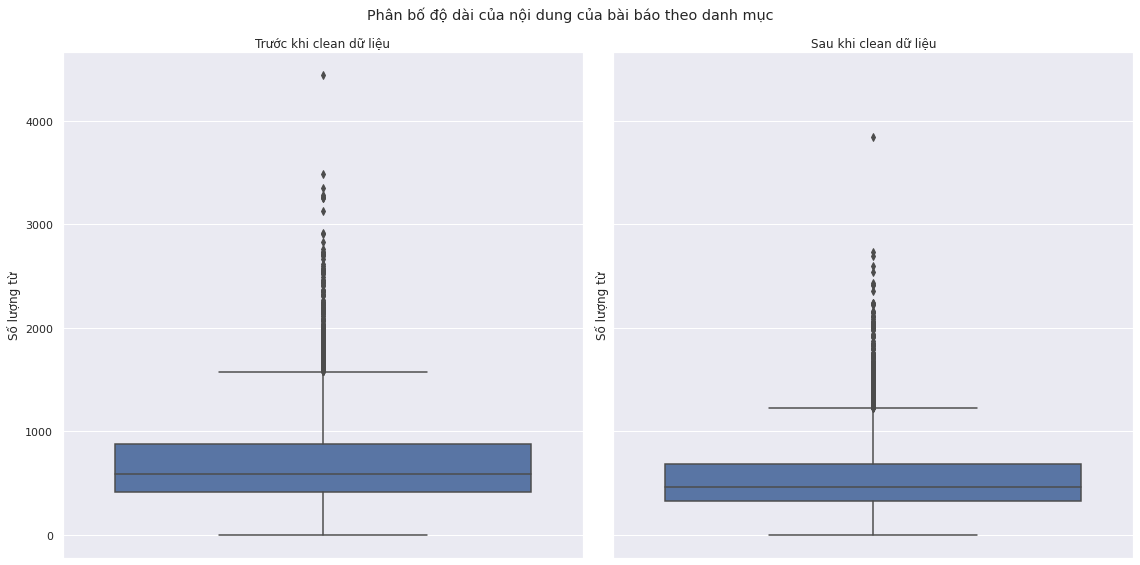

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 8), sharey=True)
for i in range(2):
  ax = axes[i]
  ndata=lm_news_raw.drop(columns='category')
  if i==1:
    ndata=lm_news_cleaned.drop(columns='category')
  sns.set_theme()
  sns.boxplot(data = ndata, y="content_len", ax=ax)
  ax.set_xlabel(None)
  ax.set_ylabel('Số lượng từ')
  # ax.tick_params(axis='x', rotation=90)

axes[0].set_title('Trước khi clean dữ liệu')
axes[1].set_title('Sau khi clean dữ liệu')

fig.suptitle("Phân bố độ dài của nội dung của bài báo theo danh mục")
plt.tight_layout()
plt.show()

Trước khi xử lý dữ liệu:
[('và', 59506), ('của', 50617), ('có', 45271), ('là', 37950), ('cho', 35708), ('các', 35143), ('được', 33132), ('trong', 32545), ('không', 30977), ('với', 30662), ('người', 29090), ('một', 27550), ('ở', 23519), ('đã', 23185), ('khi', 22221), ('để', 21819), ('học', 20886), ('những', 18443), ('thể', 18334), ('đến', 18126), ('từ', 17620), ('năm', 17556), ('bị', 17432), ('công', 17225), ('nhiều', 17200), ('vào', 17199), ('về', 16505), ('tại', 15804), ('sinh', 13976), ('cũng', 13861)]


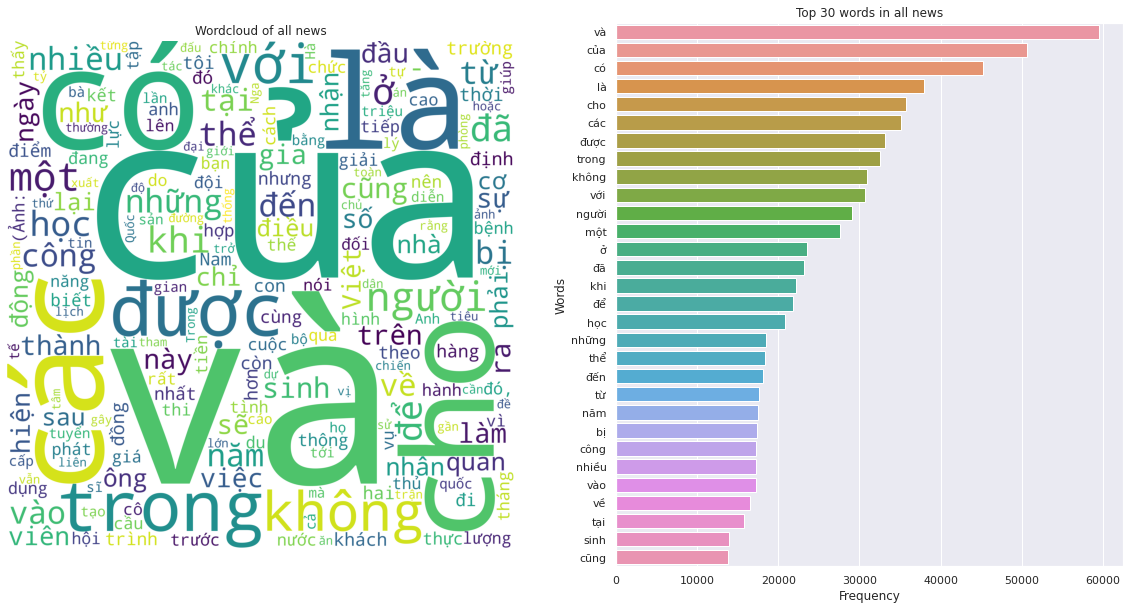

Sau khi xử lý dữ liệu:
[('ảnh', 10352), ('hai', 9765), ('đi', 8039), ('trường', 7610), ('nam', 7112), ('việt', 7020), ('nga', 5631), ('đầu', 5624), ('đồng', 5245), ('mỹ', 5214), ('tiền', 5018), ('học', 4918), ('thi', 4623), ('triệu', 4598), ('đại_học', 4488), ('ukraine', 4373), ('giúp', 4317), ('2', 4293), ('hàng', 4219), ('nguyễn', 3926), ('đường', 3689), ('gia_đình', 3605), ('tổ_chức', 3583), ('việt_nam', 3556), ('3', 3525), ('học_sinh', 3521), ('trận', 3325), ('du_lịch', 3295), ('hoạt_động', 3294), ('giải', 3233)]


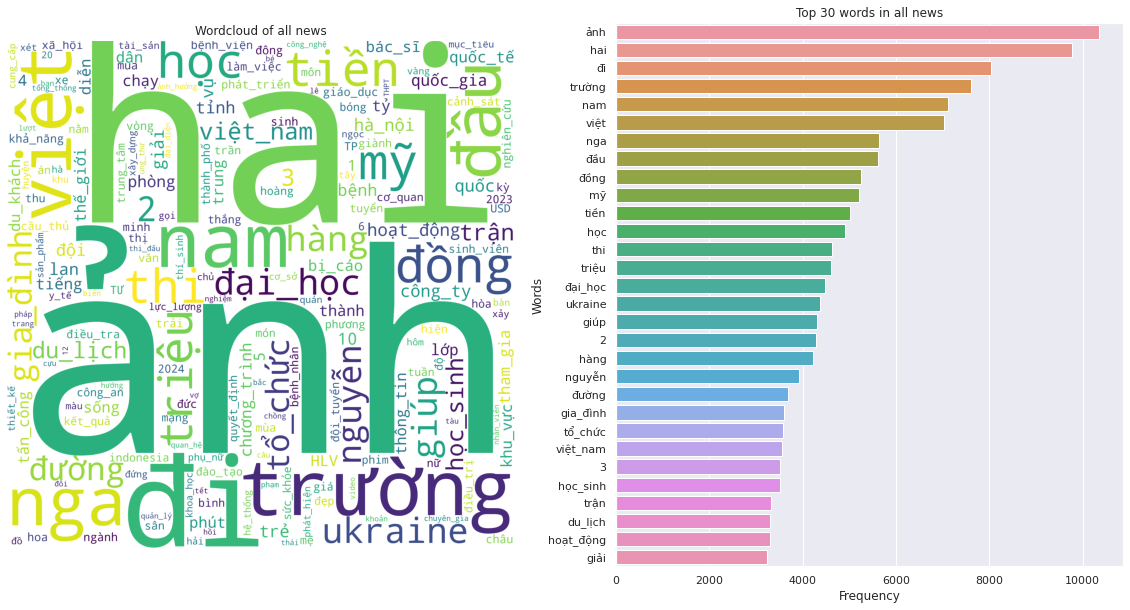

In [ ]:
print("Trước khi xử lý dữ liệu:")
draw_wordcloud_and_barplot(news_raw, "all")
print("Sau khi xử lý dữ liệu:")
draw_wordcloud_and_barplot(news_clean, "all")

Khi nhìn vào biểu đồ dữ liệu chưa xử lý ta có thể thấy các từ/cụm từ không mang ý nghĩa có tần suất xuất hiện lớn, điều này gây nhiễu đến quá trình dự đoán.

Tuy nhiên qua quá trình xử lý dữ liệu thì biểu đồ phía dưới đã biểu hiện rõ những từ/cụm từ mang ý nghĩa trong quá trình phân loại hay dự đoán chủ đề của bài báo,

Đơn cử như các từ / cụm từ:

`đại_học`, `trường` thuộc chủ đề `Giáo dục`

 `nga`, `ukraine` thuộc chủ đề `Thế giới`

### Lấy mỗi chủ đề 600 mẫu

In [ ]:
num_samples = 600

In [ ]:
data = {
    "Thế giới": news.query("category == 'Thế giới'").sort_values(by="time", ascending=False).reset_index(drop=True)[:num_samples],
    "Giáo dục": news.query("category == 'Giáo dục'").sort_values(by="time", ascending=False).reset_index(drop=True)[:num_samples],
    "Pháp luật": news.query("category == 'Pháp luật'").sort_values(by="time", ascending=False).reset_index(drop=True)[:num_samples],
    "Thể thao": news.query("category == 'Thể thao'").sort_values(by="time", ascending=False).reset_index(drop=True)[:num_samples],
    "Du lịch": news.query("category == 'Du lịch'").sort_values(by="time", ascending=False).reset_index(drop=True)[:num_samples],
    "Sức khỏe" : news.query("category == 'Sức khỏe'").sort_values(by="time", ascending=False).reset_index(drop=True)[:num_samples],
    'Giải trí': news.query("category == 'Giải trí'").sort_values(by="time", ascending=False).reset_index(drop=True)[:num_samples],
    'Đời sống': news.query("category == 'Đời sống'").sort_values(by="time", ascending=False).reset_index(drop=True)[:num_samples],
}

In [ ]:
news_600_sample = pd.concat(data.values(), ignore_index=True)

In [ ]:
news_600_sample.groupby('category').size()

category
Du lịch      600
Giáo dục     600
Giải trí     576
Pháp luật    600
Sức khỏe     600
Thế giới     600
Thể thao     600
Đời sống     600
dtype: int64

In [ ]:
news_600_sample.to_csv("clean_data/news_600_samples_each_category.csv", index=False)

# 3. Trực quan hóa dữ liệu

**Tải file dữ liệu đã được clean:** news_600_samples_each_category.csv

In [ ]:
!gdown 1m4GDLtQimD1wlN7uIKR4kg4sIcVO88ZC

Downloading...
From: https://drive.google.com/uc?id=1m4GDLtQimD1wlN7uIKR4kg4sIcVO88ZC
To: /content/news_600_samples_each_category.csv
100% 13.6M/13.6M [00:00<00:00, 93.9MB/s]


**Đọc file news_600_samples_each_category.csv vào DataFrame cleaned_news**

In [ ]:
cleaned_news = pd.read_csv("news_600_samples_each_category.csv")

Sử dụng thư viện seaborn và thư viện matplotlib
để vẽ đồ thị trực quan hóa dữ liệu

*   *pip install seaborn*
*   *pip install matplotlib*



In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# plt.figure(figsize=(8, 6))  # Adjust width and height as needed
# sns.countplot(cleaned_news, x="category", palette='viridis', saturation=1, width=0.6)
# plt.tight_layout()
# plt.show()

## 3.1. Thống kê dữ liệu trên miền thời gian

Copy DataFrame cleaned_news vào ts_news <br>
Sử dụng ts_news để thực hiện vẽ đồ thị, thống kê dữ liệu

In [ ]:
ts_news = cleaned_news

In [ ]:
ts_news['time'] = pd.to_datetime(ts_news['time'])           # convert dtype cột time từ str sang datetime
ts_news['year_month'] = ts_news['time'].dt.to_period('M')   # định dạng dữ liệu cột time từ YYYY-mm-dd HH:MM sang YYYY-mm

Padding dữ liệu thời gian cho DataFrame để vẽ đồ thị

In [ ]:
all_months = pd.period_range(start=ts_news['year_month'].min(), end=ts_news['year_month'].max(), freq='M')

In [ ]:
all_categories = ts_news['category'].unique()
mindex = pd.MultiIndex.from_product([all_months, all_categories], names=['year_month', 'category'])

In [ ]:
ts_grouped = ts_news.groupby(['year_month', 'category']).size().reset_index(name='count')
ts_grouped

,year_month,category,count
0,2012-10,Sức khỏe,1
1,2020-07,Du lịch,1
2,2020-08,Du lịch,1
3,2020-09,Du lịch,4
4,2020-09,Sức khỏe,2
...,...,...,...
150,2024-04,Pháp luật,8
151,2024-04,Sức khỏe,33
152,2024-04,Thế giới,21
153,2024-04,Thể thao,16


In [ ]:
ts_grouped = ts_grouped.set_index(['year_month', 'category'])

In [ ]:
ts_grouped = ts_grouped.reindex(mindex, fill_value=0)

In [ ]:
ts_grouped

count
year_month category        
2012-10    Du lịch        0
           Giáo dục       0
           Giải trí       0
           Pháp luật      0
           Sức khỏe       1
...                     ...
2024-04    Pháp luật      8
           Sức khỏe      33
           Thế giới      21
           Thể thao      16
           Đời sống      10

[1112 rows x 1 columns]

In [ ]:
ts_grouped = ts_grouped.reset_index()

In [ ]:
ts_grouped['year_month'] = ts_grouped['year_month'].astype(str)

**Thống kê tổng số lượng bài báo theo thời gian**

In [ ]:
ts_grouped_sum = ts_grouped.groupby('year_month').sum()
ts_grouped_sum.reset_index()[["year_month", "count"]]

,year_month,count
0,2012-10,1
1,2012-11,0
2,2012-12,0
3,2013-01,0
4,2013-02,0
...,...,...
134,2023-12,91
135,2024-01,179
136,2024-02,601
137,2024-03,3198


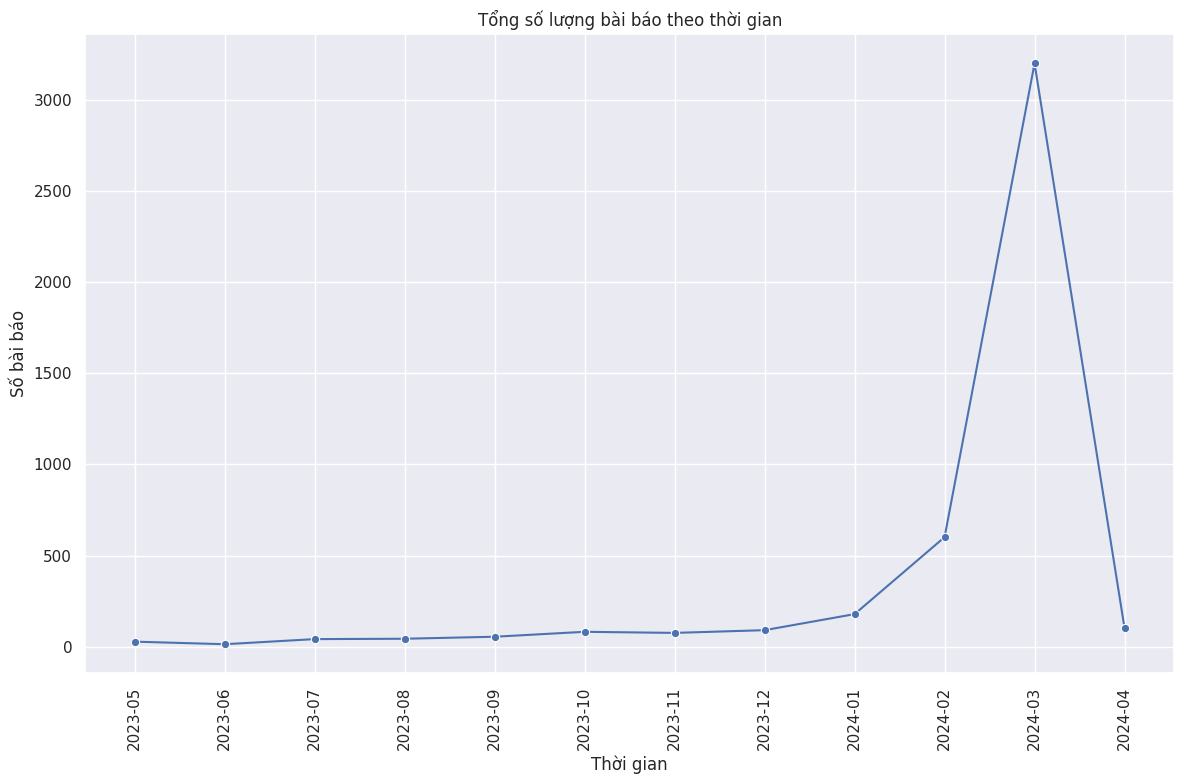

In [ ]:
plt.figure(figsize=(12, 8))
sns.set_theme()
sns.lineplot(ts_grouped_sum[-12:], x='year_month', y='count', marker='o')
plt.title('Tổng số lượng bài báo theo thời gian')
plt.xlabel('Thời gian')
plt.ylabel('Số bài báo')
plt.xticks(rotation=90)  # Rotate x-labels for better readability
plt.tight_layout()
plt.show()

Ta thấy số lượng bài báo được crawl tập trung ở 3 tháng đầu năm 2024. Đặc biệt là ở tháng 3/2024. <br>
Lý do là vì thời điểm crawl dữ liệu là vào đầu tháng 4/2024, nên số lượng bài báo sẽ tập trung vào tháng 3/2024. <br> Tuy vậy có những bài báo cũ hơn (thậm chí là 2012), đó là những bài báo được trả tiền quảng cáo để được lên trang cao hơn, ta tạm thời không xét đến những bài báo cũ

**Thống kê số lượng bài báo của từng danh mục theo thời gian**

In [ ]:
categories = ts_grouped['category'].unique()
categories.sort()

Lấy dữ liệu số bài báo của từng danh mục trong 3/2024, 2/2024 và 1/2024

In [ ]:
ndata = ts_grouped[-32:-8].reset_index(drop=True)

Vẽ biểu đồ cột cho từng danh mục

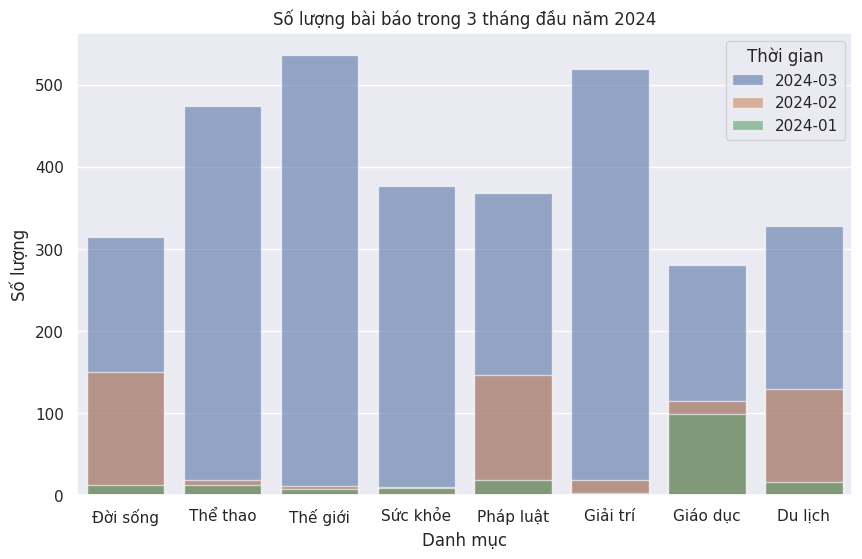

In [ ]:
plt.figure(figsize=(10, 6))
ndata = ndata.iloc[::-1]
times = ndata["year_month"].unique()
for i in range(len(times)):
  ndata_in_times = ndata.query(f"year_month == '{times[i]}'")
  sns.barplot(x='category', y='count', data=ndata_in_times, label = times[i], alpha=0.6)
plt.title('Số lượng bài báo trong 3 tháng đầu năm 2024')
plt.xlabel('Danh mục')
plt.ylabel('Số lượng')
plt.legend(title='Thời gian')
plt.show()

**Nhận xét biểu đồ** <br>
Trong tháng 3/2024, số lượng bài báo về các mục "Thế giới", "Giải trí" và "Thể thao" cao hơn các chủ đề khác <br>
Lý do vì trong tháng 3/2024, có nhiều sự kiện xảy ra thuộc 3 lĩnh vực trên:
- Thế giới: chiến sự Nga - Ukraine căng thẳng, sự can thiệp của Mỹ, bầu cử Tổng thống Nga
- Giải trí: Drama nổ ra của một số sao Hàn Quốc, các phim mới ra mắt
- Thể thao: Việt Nam tham dự vòng loại World Cup, thua trận trước Indonesia, HLV Troussier bị sa thải

Có thể áp dụng phân tích các xu hướng này để phân loại bài báo.

## 3.2. Trực quan hóa dữ liệu theo độ dài tiêu đề, mô tả, nội dung

**Tải file dữ liệu trước khi loại bỏ stop words:** news_has_stopwords_600_samples_each_category.csv <br>
Sử dụng file này để phân tích độ dài tiêu đề, mô tả, nội dung

In [ ]:
!gdown 1mATm9_ymwP-dGOhon04GHwU-ucRR4s0k

Downloading...
From: https://drive.google.com/uc?id=1mATm9_ymwP-dGOhon04GHwU-ucRR4s0k
To: /content/news_has_stopwords_600_samples_each_category.csv
100% 20.9M/20.9M [00:00<00:00, 73.9MB/s]


Đọc file news_has_stopwords_600_samples_each_category.csv vào DataFrame raw_news

In [ ]:
raw_news = pd.read_csv("news_has_stopwords_600_samples_each_category.csv")

Tính toán độ dài của tiêu đề, mô tả, nội dung của từng dòng và gán vào DataFrame lm_news_raw

In [ ]:
lm_news_raw = pd.DataFrame()

In [ ]:
lm_news_raw["title_len"] = raw_news["title"].str.split().str.len()
lm_news_raw["description_len"] = raw_news["description"].str.split().str.len()
lm_news_raw["content_len"] = raw_news["content"].str.split().str.len()
lm_news_raw["category"] = raw_news["category"]

Tương tự, tính toán độ dài của tiêu đề, mô tả, nội dung của từng dòng trong cleaned_news và gán vào DataFrame lm_news_cleaned

In [ ]:
lm_news_cleaned = pd.DataFrame()

*cleaned_news: DataFrame chứa dữ liệu đã loại bỏ stop words*

In [ ]:
lm_news_cleaned["title_len"] = cleaned_news["title"].str.split().str.len()
lm_news_cleaned["description_len"] = cleaned_news["description"].str.split().str.len()
lm_news_cleaned["content_len"] = cleaned_news["content"].str.split().str.len()
lm_news_cleaned["category"] = cleaned_news["category"]

**Vẽ biểu đồ thể hiện độ dài của tiêu đề, mô tả và nội dung trước và sau khi loại bỏ stop words**

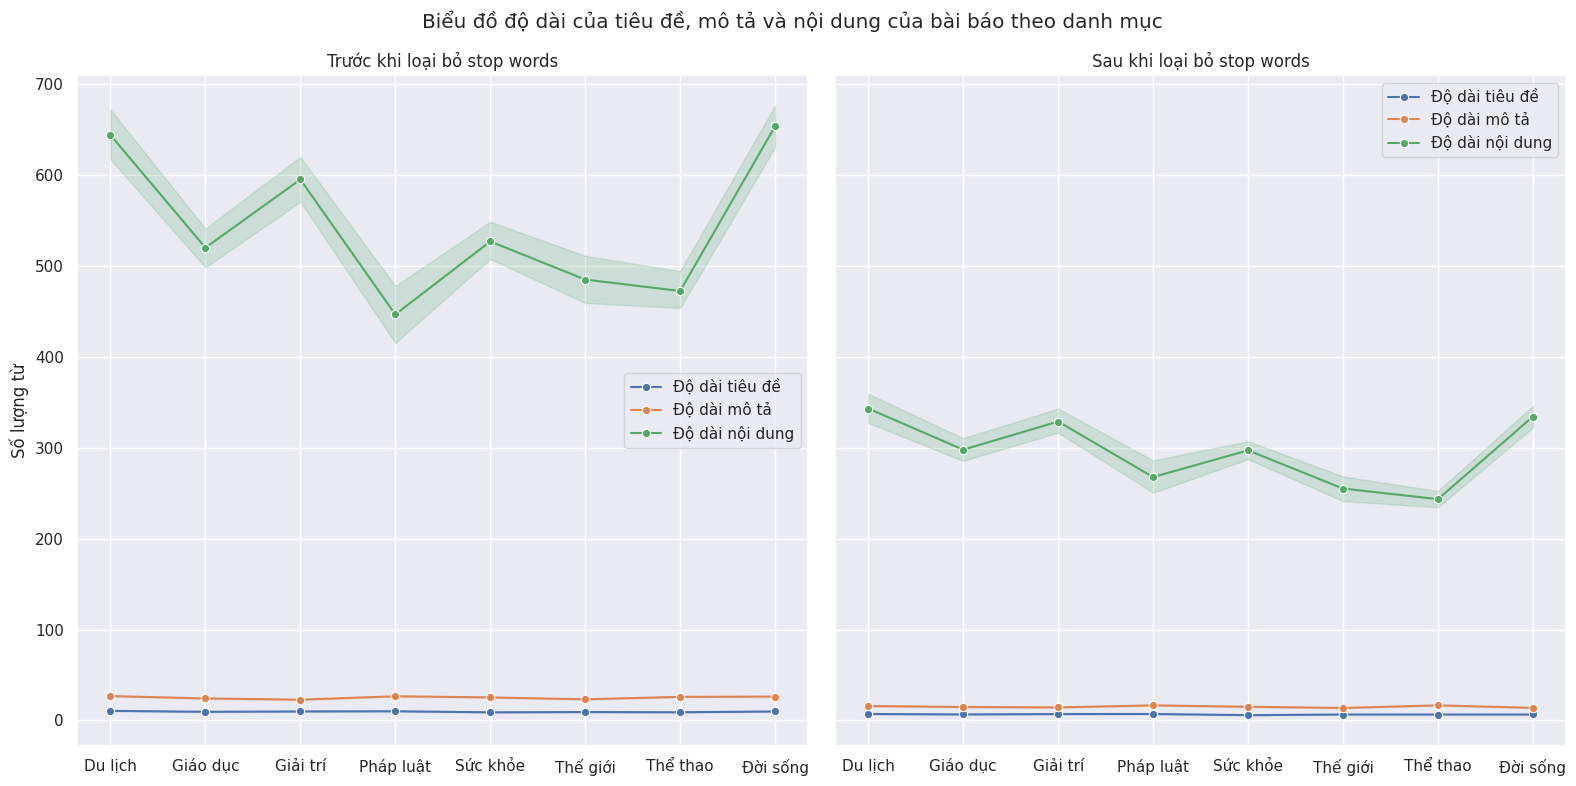

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 8), sharey=True)
for i in range(2):
  ax = axes[i]
  ndata=lm_news_raw
  if i==1:
    ndata=lm_news_cleaned
  ndata = ndata.sort_values(by='category')
  sns.set_theme()
  sns.lineplot(ndata, x='category', y='title_len', marker='o', label="Độ dài tiêu đề", ax=ax)
  sns.lineplot(ndata, x='category', y='description_len', marker='o', label="Độ dài mô tả", ax=ax)
  sns.lineplot(ndata, x='category', y='content_len', marker='o', label="Độ dài nội dung", ax=ax)
  ax.set_xlabel(None)
  ax.set_ylabel('Số lượng từ')
  # ax.tick_params(axis='x', rotation=90)

axes[0].set_title('Trước khi loại bỏ stop words')
axes[1].set_title('Sau khi loại bỏ stop words')

fig.suptitle("Biểu đồ độ dài của tiêu đề, mô tả và nội dung của bài báo theo danh mục")
plt.tight_layout()
plt.show()

**Nhận xét biểu đồ:** <br>
*Trước khi loại bỏ stop words*
- Độ dài của tiêu đề và mô tả không có sự khác biệt đáng kể qua từng danh mục
  -> Khó sử dụng độ dài của tiêu đề và nội dung để phân loại danh mục
- Độ dài của nội dung có biên độ dao động lớn:
  + Mục Đời sống và Du lịch có độ dài tương tự nhau và lớn nhất: khoảng 650 từ/bài báo
  + Mục Giáo dục và Sức khỏe có độ dài tương tự nhau
  + Mục Pháp luật (450 từ/bài) và Thể thao (480 từ/bài) có độ dài nhỏ nhất

*Sau khi loại bỏ stop words:* <br>
- Độ dài tiêu đề và mô tả có giảm nhẹ, tuy vậy vị trí tương đối không có thay đổi
- Độ dài nội dung có giảm, thứ tự có sự thay đổi nhẹ: Thể thao là mục có độ dài nhỏ nhất, tiếp theo là Thế giới

Kết luận: độ dài nội dung là yếu tố tiềm năng để phân loại danh mục bài báo

**Vẽ biểu đồ thể hiện phân bố độ dài của nội dung trước và sau khi loại bỏ stop words trên từng danh mục**

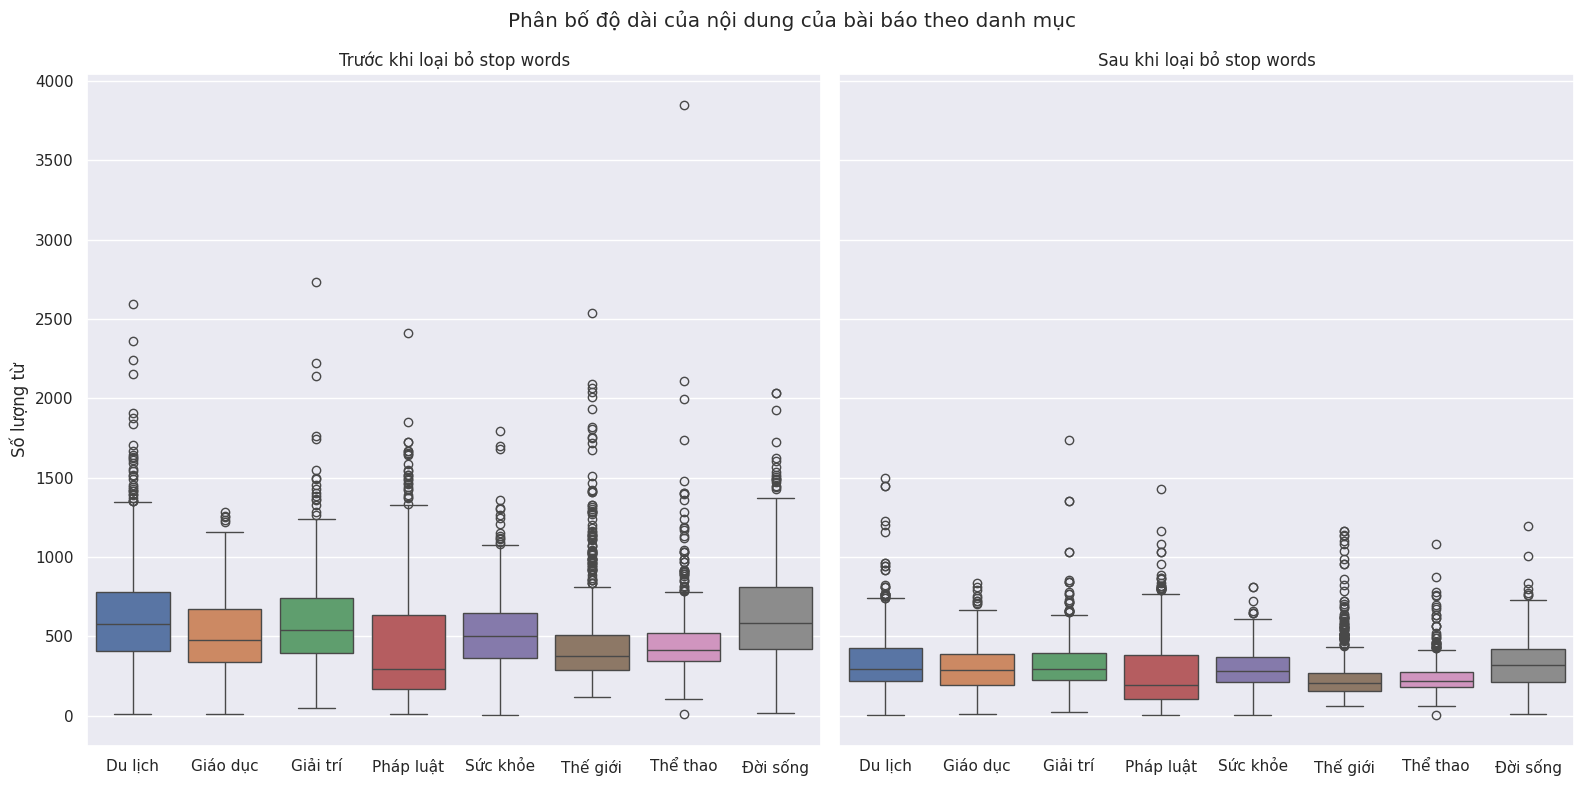

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 8), sharey=True)
for i in range(2):
  ax = axes[i]
  ndata=lm_news_raw
  if i==1:
    ndata=lm_news_cleaned
  ndata = ndata.sort_values(by='category')
  sns.set_theme()
  sns.boxplot(data = ndata, x="category", y="content_len", hue="category", ax=ax)
  ax.set_xlabel(None)
  ax.set_ylabel('Số lượng từ')
  # ax.tick_params(axis='x', rotation=90)

axes[0].set_title('Trước khi loại bỏ stop words')
axes[1].set_title('Sau khi loại bỏ stop words')

fig.suptitle("Phân bố độ dài của nội dung của bài báo theo danh mục")
plt.tight_layout()
plt.show()

**Nhận xét biểu đồ:**<br>
- Có sự khác nhau về mức độ phân bố số lượng từ trên từng danh mục:
  + Mục Đời sống và Du lịch có số lượng từ lớn nhất, mục Thể thao và Thế giới có số lượng từ nhỏ nhất
  + Tuy nhiên, khi xem xét trung vị, không có sự khác biệt lớn giữa các mục Du lịch, Giáo dục, Giải trí và Đời sống; mục Thế giới và Thể thao cũng có dữ liệu khá tương đồng

Độ dài của bài báo còn phụ thuộc vào nhiều yếu tố ngoại cảnh như ý muốn của nhà xuất bản, phong cách của nhà báo, ...

***Vì vậy, việc phân tích độ dài nội dung để phân loại danh mục chỉ có hiệu quả ở mức độ nhất định, cần phải kết hợp với các phương pháp khác (phân tích từ khóa, đánh giá xu hướng, phân tích chủ đề) để đưa ra nhận định chính xác nhất.***

## 3.3. Trực quan hóa dữ liệu theo tiêu đề + mô tả/tóm tắt(description)

Ở phần trực quan hóa dữ liệu theo nội dung, nhóm sử dụng các thư viện wordcloud (`pip install wordcloud`) để biểu thị tần suất xuất hiện của từ trong từng chủ đề

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
from wordcloud import WordCloud
sns.set(rc={'figure.figsize':(11.7, 8.27)})

In [ ]:
news = pd.read_csv("clean_data/news_600_samples_each_category.csv")

In [ ]:
news

,title,description,content,author,time,link,category
0,hành_trình công_lý gái gốc việt vũ_trụ,xâm_hại amanda ngọc nguyễn đấu_tranh quyền nạn...,amanda ngọc nguyễn phụ_nữ gốc việt bay vũ_trụ ...,Như Tâm,2024-04-01 19:00:00,https://vnexpress.net/hanh-trinh-tim-cong-ly-c...,Thế giới
1,phụ_nữ chèo thuyền xuyên đại tây dương 61,trải phẫu_thuật thoát_vị đĩa_đệm davies chèo t...,sian davies chèo thuyền 53 cuốn_hút thuyền 6 m...,Đức Trung,2024-04-01 18:23:00,https://vnexpress.net/nguoi-phu-nu-cheo-thuyen...,Thế giới
2,iran cảnh_báo nga vụ khủng_bố nhà_hát,iran thông_báo nga khả_năng xảy chiến_dịch khủ...,tehran thông_tin moskva tấn_công khủng_bố xảy ...,Vũ Hoàng,2024-04-01 18:21:00,https://vnexpress.net/iran-co-the-da-canh-bao-...,Thế giới
3,việt nam tham_gia định_hình phát_triển tương_l...,việt_nam tổ_chức diễn_đàn tương_lai asean thể_...,tổ_chức diễn_đàn tương_lai asean aff ý_tưởng v...,Vũ Anh,2024-04-01 18:16:00,https://vnexpress.net/viet-nam-tham-gia-dinh-h...,Thế giới
4,xóa_hình xăm sám_hối ramadan,100 jakarta đăng_ký xóa_hình xăm miễn_phí rama...,bima abdul sholeh 32 im bác_sĩ chiếu đèn laser...,Hồng Hạnh,2024-04-01 17:54:00,https://vnexpress.net/xoa-hinh-xam-de-sam-hoi-...,Thế giới
...,...,...,...,...,...,...,...
4771,tươi_trẻ cuốn_hút trang_sức emerald ưu_đãi 30,đá_quý emerald dải màu xanh lục xanh lục hơi n...,bảo tín minh châu giới_thiệu khách_hàng sưu_tậ...,Trường Thịnh,2023-05-01 08:26:00,https://dantri.com.vn/doi-song/tuoi-tre-cuon-h...,Đời sống
4772,cụ đi vệ_sinh đường_ray bò rơi trúng tử_vong t...,cụ ấn_độ tử_vong tại_chỗ sự_cố hy_hữu xảy bò r...,vụ tai_nạn kinh_hoàng xảy tuyến đường_ray xe l...,Huy Hoàng,2023-04-27 17:27:00,https://dantri.com.vn/doi-song/cu-ong-di-ve-si...,Đời sống
4773,cháy nổ bình ga nguy_cơ tiềm_ẩn gia_đình,thói_quen tưởng_chừng đơn_giản nguyên_nhân vụ ...,phổ_biến gia_đình việt bếp gas đáp_ứng nhu_cầu...,Tiến Thịnh,2023-04-26 13:58:00,https://dantri.com.vn/doi-song/chay-no-binh-ga...,Đời sống
4774,chăm_sóc sức_khỏe ghế herman miller aeron 2,mẫu ghế herman miller aeron giảm_thiểu áp_lực ...,herman miller thành_lập 1905 thành_phố zeeland...,Tiến Thịnh,2023-04-26 12:28:00,https://dantri.com.vn/doi-song/cham-soc-suc-kh...,Đời sống


In [ ]:
# The `words_frequency` function is a Python function that calculates the frequency of words in a given dataset based on a specified category and column name.
def words_frequency(data, category, column_name="content"):
    words_count = {}

    if category == "all":
        query_category = data[column_name].str.split().dropna().sum()
    else:
        query_category = data.query(f"category == '{category}'")[column_name].str.split().dropna().sum()
    for word in query_category:
        if word in words_count:
            words_count[word] += 1
        else:
            words_count[word] = 1

    return words_count

from wordcloud import WordCloud
# The `wordcloud_draw` function is generating a word cloud visualization based on the frequency of words in a given dataset.
def wordcloud_draw(data, category, color = 'white', column_name="content"):
    wordcloud = WordCloud(background_color = color, width = 2500, height = 2500).generate_from_frequencies(words_frequency(data, category, column_name))
    return wordcloud

# The `draw_wordcloud_and_barplot` function is a Python function that generates a visualization containing a word cloud and a bar plot based on the frequency of words in a given dataset.
def draw_wordcloud_and_barplot(data, category, column_name = "content"):
    fig, ax = plt.subplots(1, 2, figsize=(20, 10))
    ax[0].imshow(wordcloud_draw(data, category, 'white', column_name))
    ax[0].axis('off')
    ax[0].set_title(f"Wordcloud of {category} news")

    words_freq = words_frequency(data, category, column_name)
    words_freq = sorted(words_freq.items(), key=lambda x: x[1], reverse=True)
    print(words_freq[:30])
    ax[1] = sns.barplot(y=[x[0] for x in words_freq[:30]], x=[x[1] for x in words_freq[:30]], orient='h')
    ax[1].set_xlabel("Frequency")
    ax[1].set_ylabel("Words")
    ax[1].set_title(f"Top 30 words in {category} news")
    plt.show()

In [ ]:
news["title_description"] = news["title"] + " " + news["description"]

#### Du lịch
Từ biểu đồ ta có thể thấy chủ đề du lịch có các từ hoặc cụm từ phổ biến như: `du_lịch`, `du_khách`, `việt`, `hà_nội`,...

Những từ hoặc cụm từ này có liên quan đến lĩnh vực `Du lịch`

[('du_lịch', 232), ('du_khách', 211), ('việt', 139), ('hà_nội', 105), ('đi', 100), ('nam', 96), ('hàng', 95), ('quán', 85), ('quốc', 80), ('món', 78), ('hoa', 78), ('đồng', 76), ('trải', 74), ('thế_giới', 71), ('việt_nam', 69), ('nghiệm', 69), ('triệu', 65), ('quốc_tế', 61), ('giá', 59), ('tết', 58), ('vé', 56), ('thu_hút', 55), ('đầu', 54), ('đà_nẵng', 52), ('hội', 51), ('trung', 50), ('chuyến', 49), ('núi', 49), ('2024', 47), ('máy_bay', 46)]


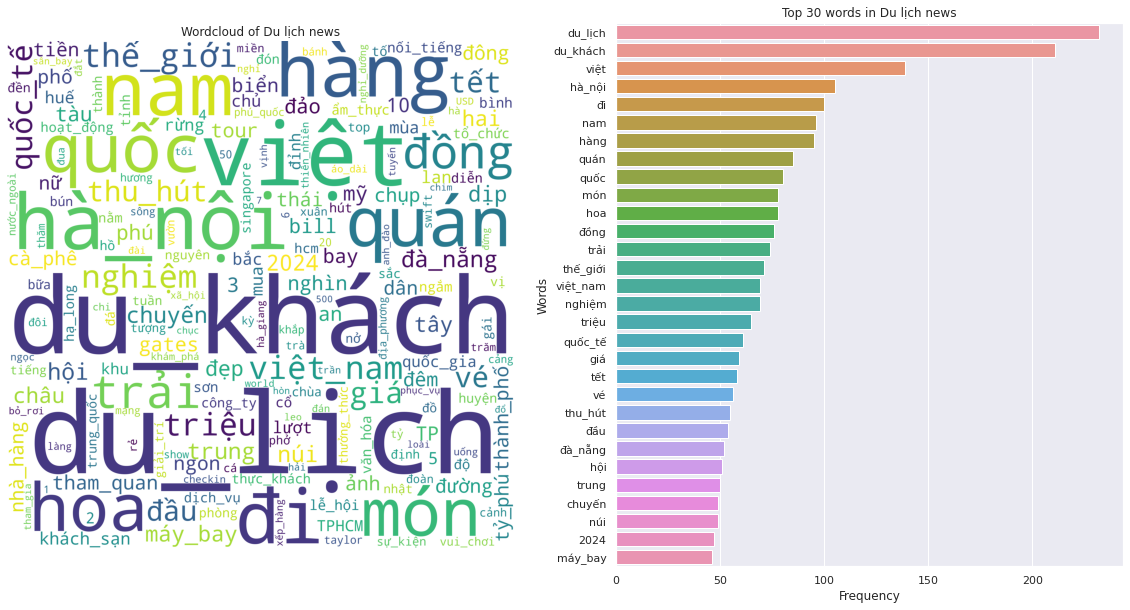

In [ ]:
draw_wordcloud_and_barplot(news, 'Du lịch', "title_description")

#### Giáo dục
Từ biểu đồ ta có thể thấy chủ đề giáo dục có các từ hoặc cụm từ phổ biến như: `trường`, `đại_học`, `học_sinh`, `lớp`,...

Những từ hoặc cụm từ này có liên quan đến lĩnh vực `Giáo dục`

[('trường', 386), ('đại_học', 254), ('thi', 227), ('học_sinh', 199), ('lớp', 190), ('học', 151), ('10', 109), ('quốc_tế', 108), ('sinh_viên', 101), ('tuyển', 101), ('hà_nội', 99), ('nam', 97), ('giáo_dục', 96), ('ngành', 91), ('đào_tạo', 90), ('tốt_nghiệp', 85), ('đồng', 84), ('2024', 82), ('tuyển_sinh', 78), ('mỹ', 78), ('việt', 76), ('chuyên', 73), ('xét', 70), ('tiếng', 69), ('THPT', 68), ('việt_nam', 67), ('hai', 67), ('tỉnh', 65), ('phụ_huynh', 61), ('thí_sinh', 60)]


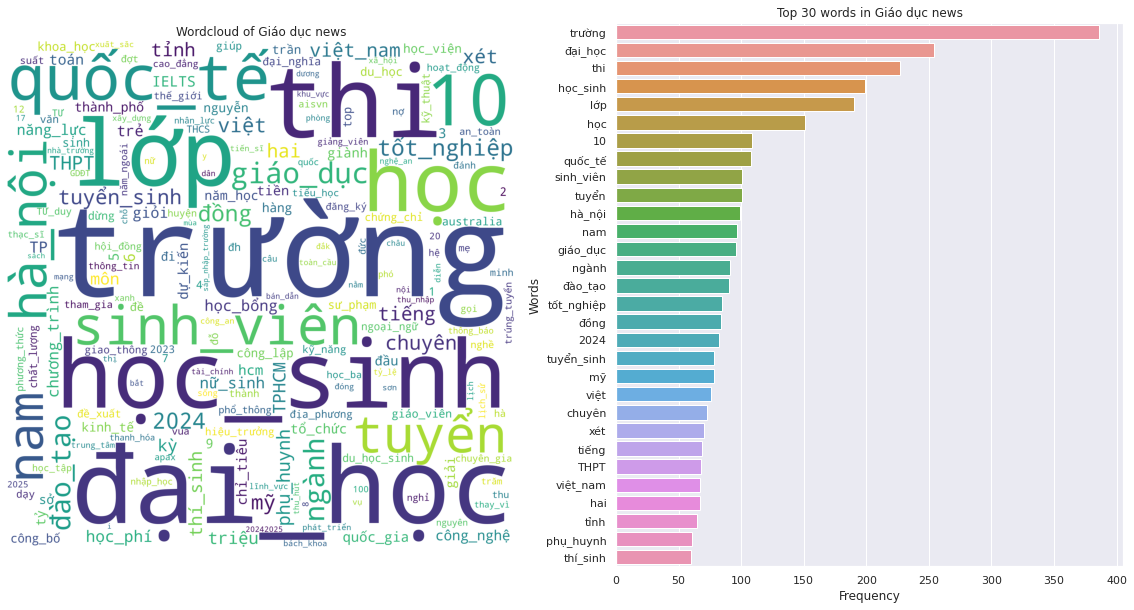

In [ ]:
draw_wordcloud_and_barplot(news, 'Giáo dục', "title_description")

#### Giải trí
Từ biểu đồ ta có thể thấy chủ đề giải trí có các từ hoặc cụm từ phổ biến như: `phim`, `diễn viên`, `ca_sĩ`, `nữ`,..

Những từ hoặc cụm từ này có liên quan đến lĩnh vực `Giải trí`

[('phim', 100), ('diễn_viên', 92), ('việt', 70), ('ca_sĩ', 69), ('nữ', 66), ('kim', 59), ('hàn', 57), ('thời_trang', 56), ('chồng', 55), ('đẹp', 53), ('triệu', 50), ('han', 50), ('hoa_hậu', 50), ('nam', 49), ('hee', 48), ('2024', 48), ('ngọc', 45), ('oscar', 44), ('ảnh', 44), ('quốc', 43), ('chú_ý', 42), ('vợ', 40), ('thi', 40), ('khán_giả', 38), ('mai', 38), ('hai', 38), ('mỹ_nhân', 37), ('trai', 36), ('đóng', 36), ('mặc', 36)]


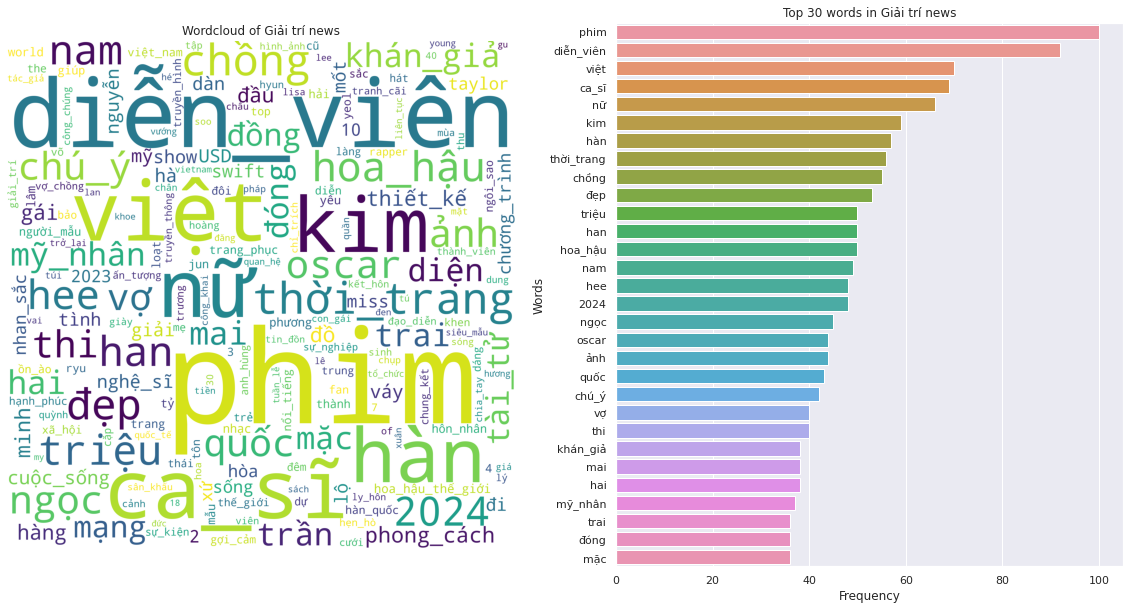

In [ ]:
draw_wordcloud_and_barplot(news, 'Giải trí', "title_description")

#### Pháp luật
Từ biểu đồ ta có thể thấy chủ đề pháp luật có các từ hoặc cụm từ phổ biến như: `đồng`, `tỷ`, `tiền`, `bắt`, `án`,...

Những từ hoặc cụm từ này có liên quan đến lĩnh vực `Pháp luật`

[('đồng', 217), ('tỷ', 164), ('tiền', 141), ('bắt', 131), ('án', 123), ('vụ', 115), ('trương', 97), ('triệu', 94), ('mỹ', 90), ('hoàng', 87), ('lan', 86), ('đi', 86), ('công_an', 86), ('nguyễn', 84), ('hai', 71), ('cảnh_sát', 68), ('bị_cáo_buộc', 63), ('tỉnh', 62), ('tù', 61), ('minh', 61), ('chủ_tịch', 58), ('lừa', 58), ('cựu', 56), ('tài_sản', 56), ('tân', 55), ('chiếm_đoạt', 54), ('mua', 53), ('scb', 52), ('giám_đốc', 51), ('thị', 51)]


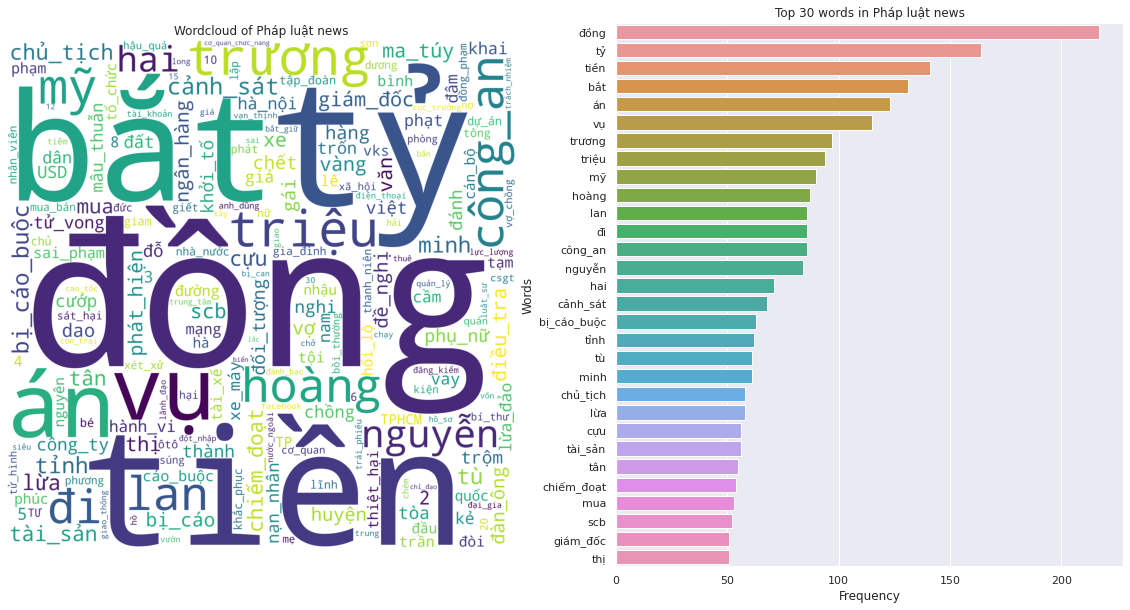

In [ ]:
draw_wordcloud_and_barplot(news, 'Pháp luật', "title_description")

#### Sức khỏe
Từ biểu đồ ta có thể thấy chủ đề sức khỏe có các từ hoặc cụm từ phổ biến như: `bệnh`, `ung_thư`, `bệnh_viện`, `bác_sĩ`,...

Những từ hoặc cụm từ này có liên quan đến lĩnh vực `Sức khỏe`

[('bệnh', 158), ('ung_thư', 123), ('bệnh_viện', 100), ('bác_sĩ', 95), ('tim', 86), ('mắc', 82), ('sức_khỏe', 81), ('nguy_cơ', 80), ('bệnh_nhân', 79), ('giúp', 76), ('đau', 72), ('điều_trị', 67), ('máu', 65), ('y_tế', 64), ('trẻ', 62), ('gan', 59), ('phát_hiện', 59), ('viêm', 57), ('uống', 55), ('đi', 55), ('phụ_nữ', 53), ('da', 49), ('nam', 49), ('tử_vong', 48), ('phổi', 48), ('bé', 47), ('khám', 46), ('ca', 45), ('nhập_viện', 42), ('đàn_ông', 42)]


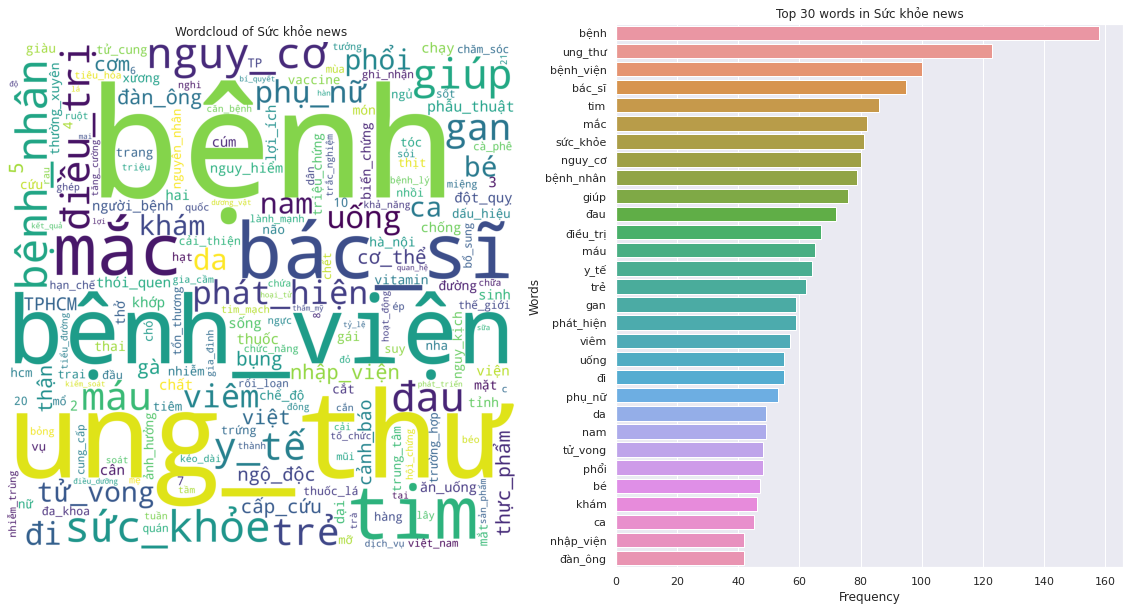

In [ ]:
draw_wordcloud_and_barplot(news, 'Sức khỏe', "title_description")

#### Thế giới
Từ biểu đồ ta có thể thấy chủ đề thế giới có các từ hoặc cụm từ phổ biến như: `nga`, `ukraine`, `mỹ`, `vụ`, `khủng_bố`,...

Những từ hoặc cụm từ này có liên quan đến lĩnh vực `Thế giới`

[('nga', 515), ('ukraine', 391), ('mỹ', 183), ('vụ', 154), ('khủng_bố', 146), ('tấn_công', 135), ('tổng_thống', 123), ('tên_lửa', 106), ('nhà_hát', 99), ('tàu', 80), ('trump', 78), ('cầu', 64), ('quốc', 58), ('tập_kích', 57), ('tuyên_bố', 55), ('moscow', 52), ('sập', 51), ('cảnh_báo', 50), ('quân_đội', 50), ('nghi', 50), ('israel', 49), ('kiev', 49), ('trung', 49), ('biden', 44), ('tây', 43), ('UAV', 43), ('hai', 42), ('lan', 42), ('phạm', 42), ('hàng', 41)]


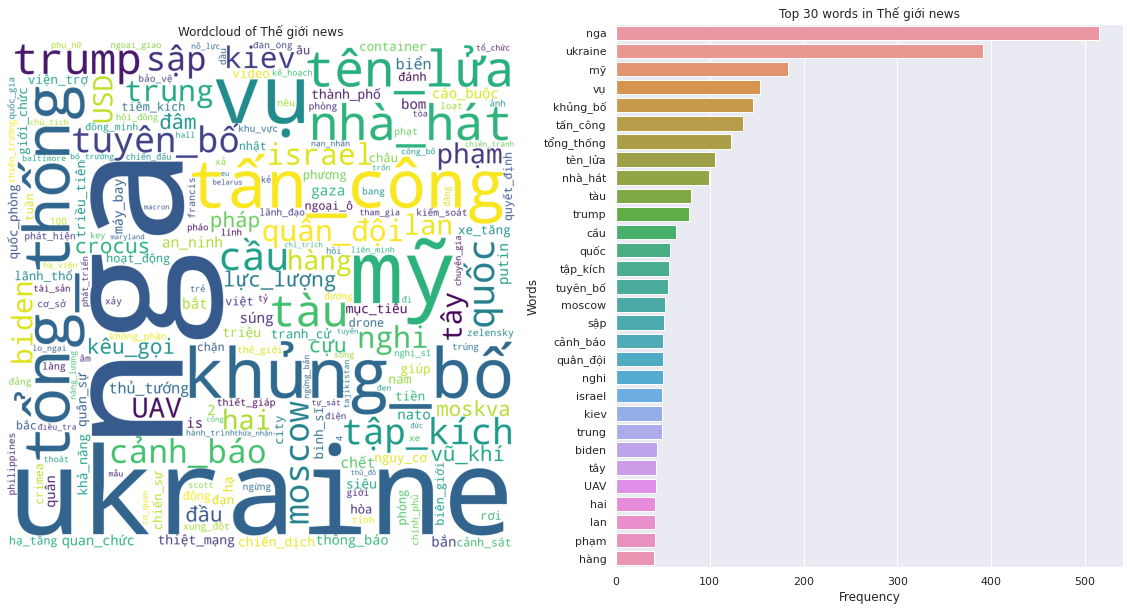

In [ ]:
draw_wordcloud_and_barplot(news, 'Thế giới', "title_description")

#### Thể thao
Từ biểu đồ ta có thể thấy chủ đề thể thao có các từ hoặc cụm từ phổ biến như: `HLV`, `trận`, `indonesia`, `việt_nam`,...

Những từ hoặc cụm từ này có liên quan đến lĩnh vực `Thể thao`

[('HLV', 320), ('indonesia', 273), ('nam', 220), ('việt_nam', 213), ('việt', 193), ('trận', 183), ('đội_tuyển', 171), ('troussier', 148), ('hai', 123), ('thắng', 122), ('vòng_loại', 122), ('giải', 121), ('world_cup', 119), ('2026', 113), ('vòng', 103), ('man', 100), ('thua', 99), ('2024', 93), ('đội', 92), ('sân', 91), ('thế_giới', 85), ('vô_địch', 84), ('cầu_thủ', 82), ('tuyển', 76), ('mỹ', 71), ('châu', 66), ('chạy', 58), ('đình', 57), ('giành', 55), ('bóng_đá', 55)]


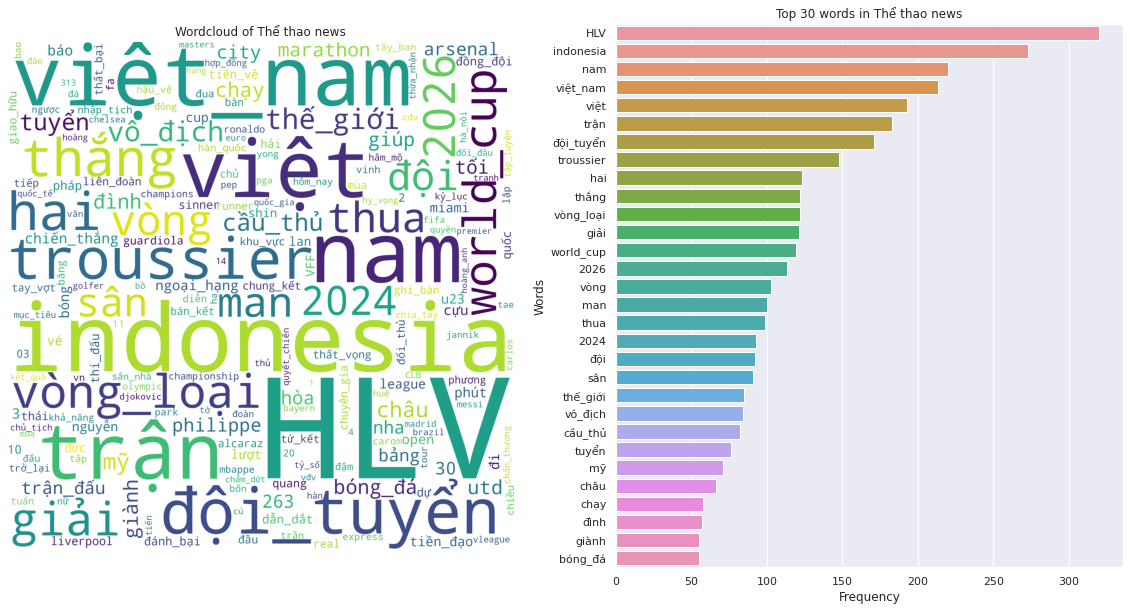

In [ ]:
draw_wordcloud_and_barplot(news, 'Thể thao', "title_description")

#### Đời sống
Từ biểu đồ ta có thể thấy chủ đề đời sống có các từ hoặc cụm từ phổ biến như: `gia_đình`, `mẹ`, `phụ_nữ`, `tết`,...
Những từ hoặc cụm từ này có liên quan đến chủ đề `Đời sống`.

Tuy nhiên các từ như `đồng`, `đi` lại mang ít ý nghĩa đối với chủ đề `Đời sống`. Điều này có thể dự đoán nhãn này khi dự đoán bằng `Tiêu đề` và `Nội dung` sẽ có nhiều kết quả dự đoán nhầm lẫn.

[('đồng', 83), ('đi', 79), ('triệu', 74), ('tết', 71), ('việt', 67), ('tiền', 64), ('phụ_nữ', 63), ('hà_nội', 61), ('gái', 57), ('hàng', 56), ('sống', 56), ('gia_đình', 56), ('quốc', 53), ('trẻ', 53), ('mạng', 48), ('hai', 46), ('mẹ', 46), ('mỹ', 45), ('mua', 45), ('trung', 42), ('dân', 42), ('cụ', 42), ('đầu', 41), ('nam', 41), ('vợ', 40), ('tỷ', 39), ('món', 38), ('trai', 37), ('chàng', 34), ('hoa', 33)]


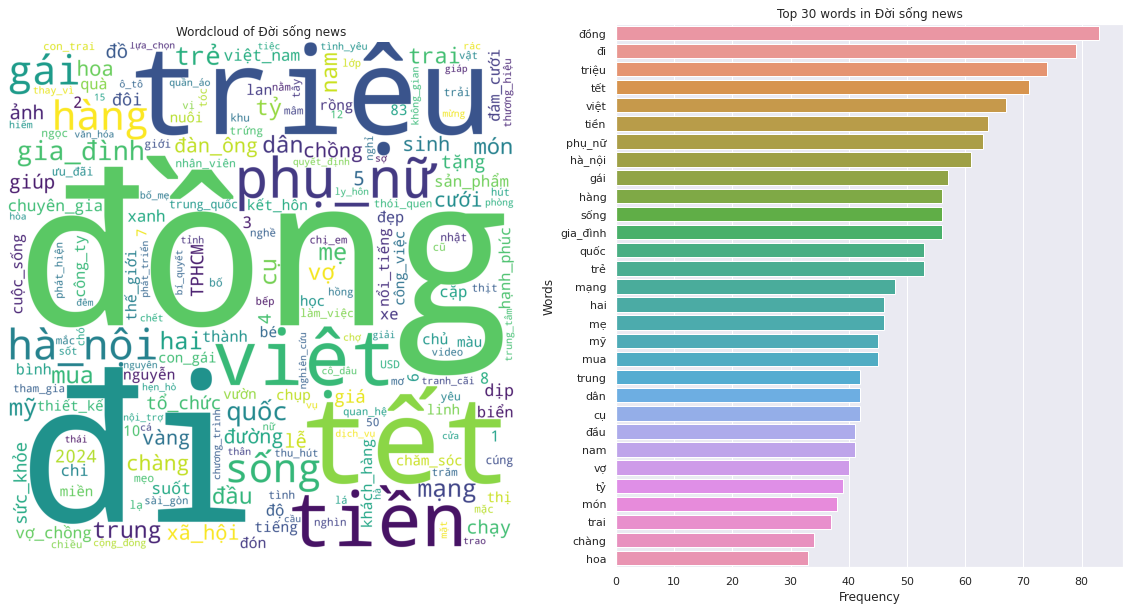

In [ ]:
draw_wordcloud_and_barplot(news, 'Đời sống', "title_description")

## 3.4. Trực quan hóa dữ liệu theo nội dung
Ở phần trực quan hóa dữ liệu theo nội dung, nhóm sử dụng các thư viện wordcloud (`pip install wordcloud`) để biểu thị tần suất xuất hiện của từ trong từng chủ đề

In [ ]:
news.groupby('category').size()

category
Du lịch      600
Giáo dục     600
Giải trí     576
Pháp luật    600
Sức khỏe     600
Thế giới     600
Thể thao     600
Đời sống     600
dtype: int64

In [ ]:
news["category"].unique()

array(['Thế giới', 'Giáo dục', 'Pháp luật', 'Thể thao', 'Du lịch',
       'Sức khỏe', 'Giải trí', 'Đời sống'], dtype=object)

#### Du lịch
Từ biểu đồ ta có thể thấy chủ đề du lịch có các từ hoặc cụm từ phổ biến như: `du_lịch`, `du_khách`, `ảnh`, `đi`,...

Những từ hoặc cụm từ này có liên quan đến lĩnh vực `Du lịch`

[('du_lịch', 2456), ('du_khách', 1989), ('ảnh', 1798), ('đi', 1558), ('nam', 1103), ('việt', 1025), ('quán', 1005), ('món', 947), ('hoa', 870), ('đồng', 838), ('hàng', 834), ('hai', 809), ('trải', 762), ('đường', 719), ('giá', 679), ('nghiệm', 672), ('triệu', 657), ('quốc', 629), ('chuyến', 613), ('đầu', 606), ('dân', 590), ('vé', 590), ('khu', 589), ('phòng', 566), ('núi', 547), ('biển', 544), ('2', 536), ('việt_nam', 535), ('đông', 531), ('3', 514)]


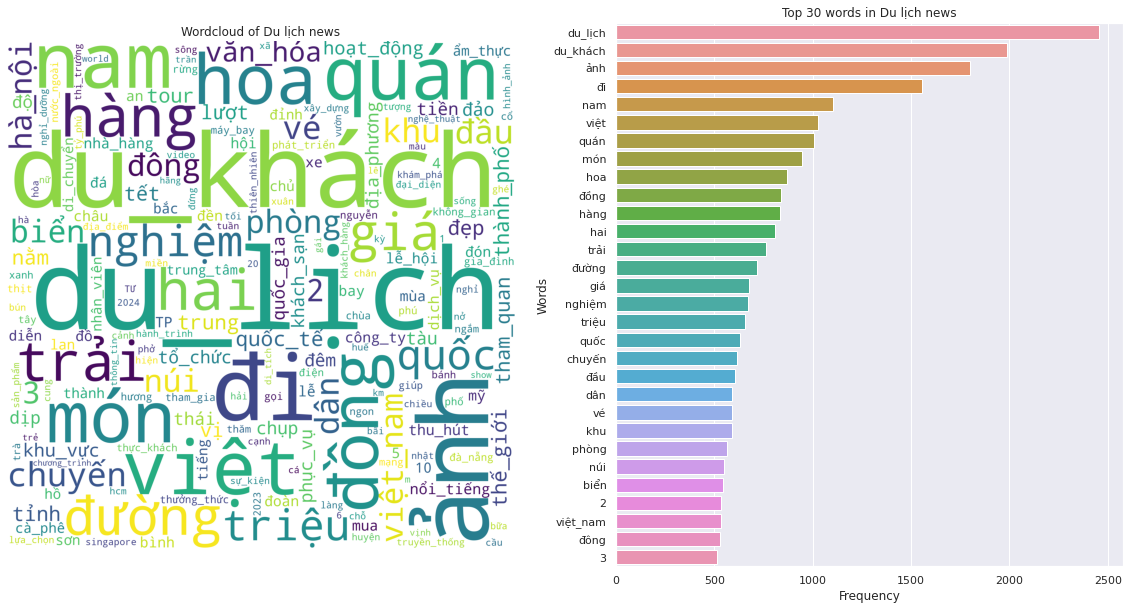

In [ ]:
draw_wordcloud_and_barplot(news, 'Du lịch', "content")

#### Giáo dục
Từ biểu đồ ta có thể thấy chủ đề giáo dục có các từ hoặc cụm từ phổ biến như: `trường`, `đại_học`, `học`, `học_sinh`,...

Những từ hoặc cụm từ này có liên quan đến lĩnh vực `Giáo dục`

[('trường', 4096), ('thi', 2457), ('học', 2020), ('đại_học', 1996), ('học_sinh', 1904), ('giáo_dục', 1266), ('lớp', 1211), ('đào_tạo', 1072), ('chương_trình', 985), ('thí_sinh', 928), ('THPT', 926), ('xét', 913), ('ngành', 899), ('tuyển', 898), ('sinh_viên', 897), ('môn', 832), ('quốc_tế', 811), ('hai', 751), ('tiếng', 748), ('chuyên', 738), ('nam', 698), ('hà_nội', 677), ('tốt_nghiệp', 673), ('tuyển_sinh', 619), ('phụ_huynh', 588), ('kỳ', 583), ('tổ_chức', 582), ('10', 569), ('khoa_học', 529), ('việt', 510)]


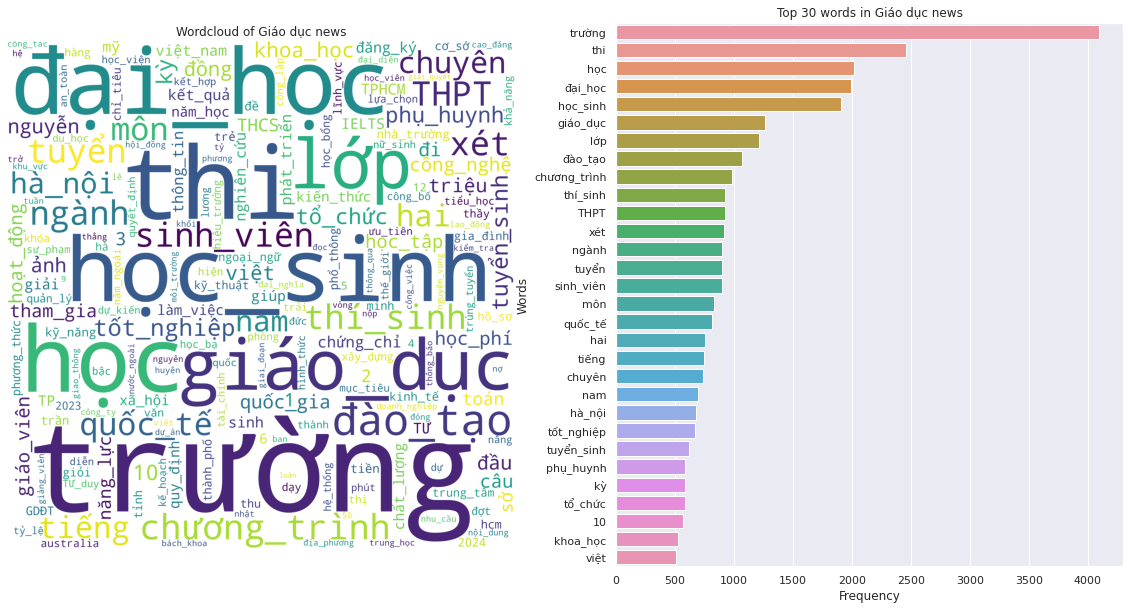

In [ ]:
draw_wordcloud_and_barplot(news, 'Giáo dục', "content")

#### Giải trí
Từ biểu đồ ta có thể thấy chủ đề giải trí có các từ hoặc cụm từ phổ biến như: `ảnh`, `phim`, `diễn_viên`,...

Những từ hoặc cụm từ này có liên quan đến lĩnh vực `Giải trí`

[('ảnh', 2249), ('phim', 1449), ('diễn_viên', 1123), ('hai', 863), ('nam', 737), ('khán_giả', 706), ('nữ', 687), ('đẹp', 674), ('ca_sĩ', 608), ('đi', 606), ('nghệ_sĩ', 604), ('việt', 586), ('thi', 570), ('diễn', 542), ('đầu', 538), ('thiết_kế', 537), ('thời_trang', 509), ('kim', 508), ('video', 494), ('vai', 490), ('giải', 479), ('nhân_vật', 478), ('tác_phẩm', 476), ('hee', 469), ('triệu', 463), ('mỹ', 423), ('han', 420), ('đóng', 413), ('tham_gia', 411), ('gia_đình', 407)]


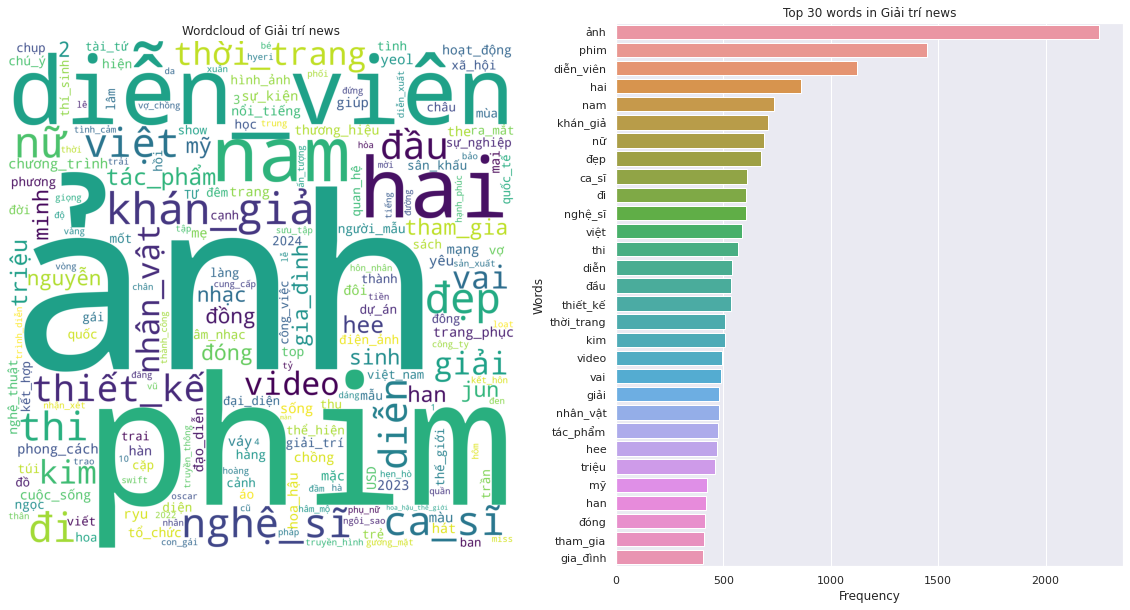

In [ ]:
draw_wordcloud_and_barplot(news, 'Giải trí', "content")

#### Pháp luật
Từ biểu đồ ta có thể thấy chủ đề pháp luật có các từ hoặc cụm từ phổ biến như: `tiền`, `bị_cáo`, `đồng`, `án`, `điều_tra`,...

Những từ hoặc cụm từ này có liên quan đến lĩnh vực `Pháp luật`

[('tiền', 1646), ('bị_cáo', 1564), ('đồng', 1378), ('lan', 1176), ('án', 1118), ('tỷ', 1099), ('công_an', 1094), ('vụ', 969), ('điều_tra', 938), ('scb', 902), ('công_ty', 854), ('tài_sản', 848), ('tỉnh', 741), ('triệu', 711), ('hoàng', 705), ('cảnh_sát', 704), ('hai', 697), ('ngân_hàng', 685), ('vay', 661), ('nguyễn', 659), ('cơ_quan', 631), ('đầu', 614), ('đi', 611), ('hành_vi', 606), ('huyện', 550), ('tội', 547), ('việt', 522), ('minh', 507), ('văn', 504), ('đề_nghị', 470)]


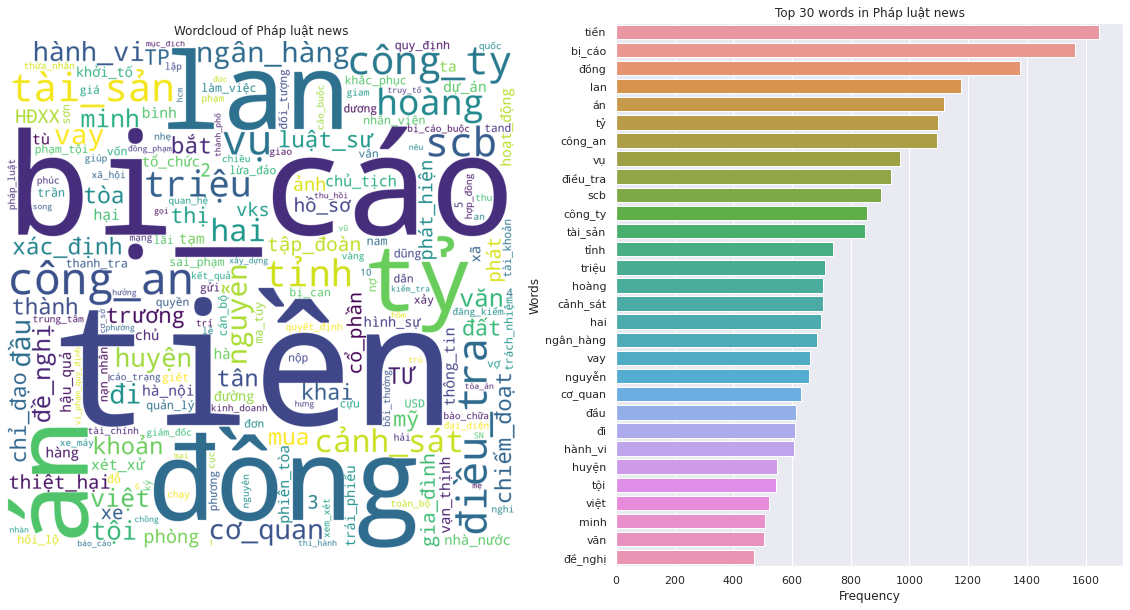

In [ ]:
draw_wordcloud_and_barplot(news, 'Pháp luật', "content")

#### Sức khỏe
Từ biểu đồ ta có thể thấy chủ đề sức khỏe có các từ hoặc cụm từ phổ biến như: `bệnh`, `bác_sĩ`, `bệnh_nhân`, `bệnh_viện`, `điều trị`,...

Những từ hoặc cụm từ này có liên quan đến lĩnh vực `Sức khỏe`

[('bệnh', 2119), ('bác_sĩ', 1461), ('bệnh_nhân', 1303), ('bệnh_viện', 1276), ('điều_trị', 1122), ('y_tế', 848), ('sức_khỏe', 840), ('ung_thư', 795), ('ảnh', 793), ('nguy_cơ', 779), ('giúp', 733), ('máu', 716), ('khám', 715), ('tim', 714), ('mắc', 687), ('viêm', 687), ('đi', 669), ('chất', 630), ('người_bệnh', 623), ('thuốc', 615), ('trẻ', 610), ('cơ_thể', 608), ('đau', 596), ('đường', 570), ('da', 568), ('phẫu_thuật', 555), ('uống', 516), ('gan', 504), ('nghiên_cứu', 503), ('ca', 482)]


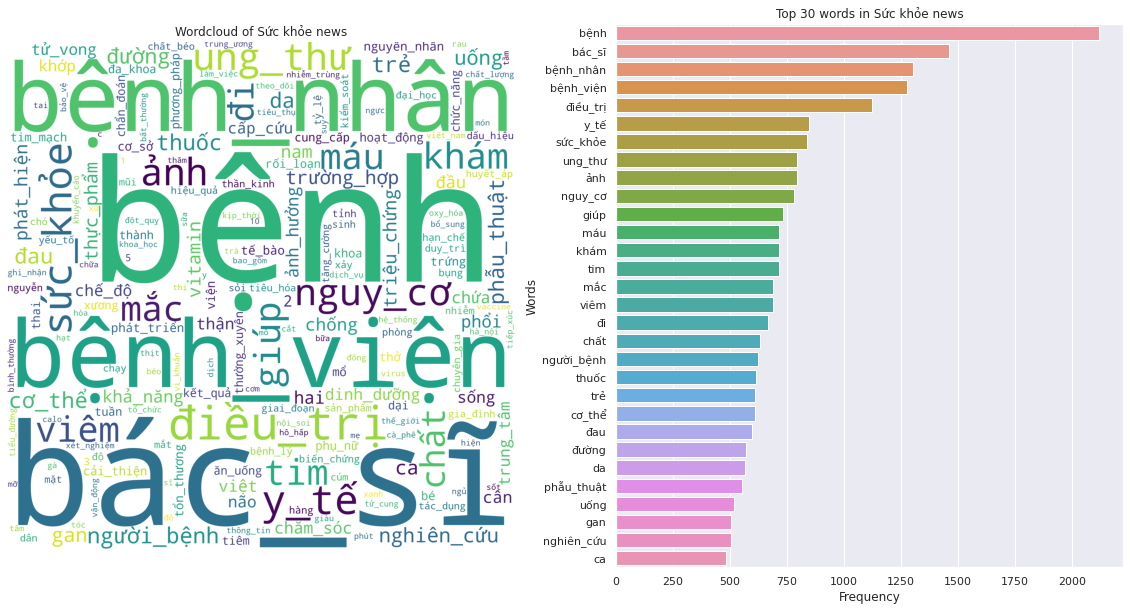

In [ ]:
draw_wordcloud_and_barplot(news, 'Sức khỏe', "content")

#### Thế giới
Từ biểu đồ ta có thể thấy chủ đề thế giới có các từ hoặc cụm từ phổ biến như: `nga`, `ukraine`, `mỹ`, `tấn_công`,...

Những từ hoặc cụm từ này có liên quan đến lĩnh vực `Thế giới`

[('nga', 3250), ('ukraine', 2690), ('tấn_công', 1413), ('mỹ', 1336), ('vụ', 1007), ('tổng_thống', 856), ('tên_lửa', 837), ('lực_lượng', 781), ('trump', 635), ('tàu', 632), ('hai', 596), ('khu_vực', 557), ('khủng_bố', 530), ('tây', 520), ('quân_đội', 516), ('đầu', 471), ('ảnh', 464), ('hàng', 457), ('hồi', 436), ('tuyên_bố', 436), ('USD', 435), ('vũ_khí', 426), ('quân_sự', 413), ('kiev', 410), ('an_ninh', 401), ('quốc_phòng', 395), ('mục_tiêu', 387), ('máy_bay', 381), ('quốc_gia', 378), ('israel', 377)]


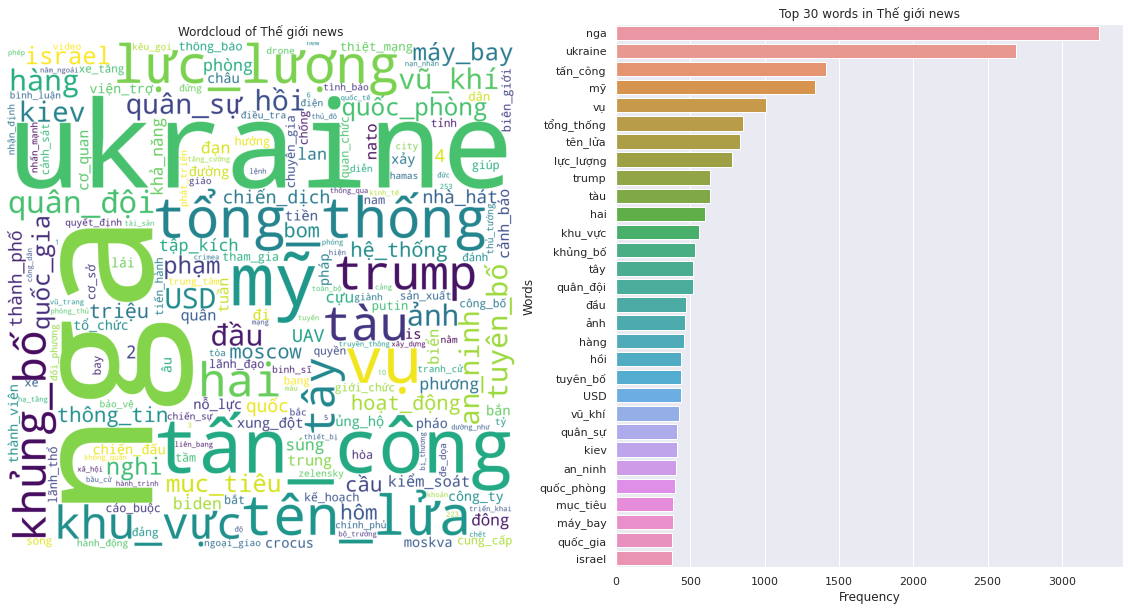

In [ ]:
draw_wordcloud_and_barplot(news, 'Thế giới', "content")

#### Thể thao
Từ biểu đồ ta có thể thấy chủ đề thể thao có các từ hoặc cụm từ phổ biến như: `trận`, `HLV`, `đội`, `cầu_thủ`, `indonesia`, `đội_tuyển`,...

Những từ hoặc cụm từ này có liên quan đến lĩnh vực `Thể thao`

[('trận', 1971), ('HLV', 1870), ('hai', 1842), ('đội', 1563), ('indonesia', 1557), ('đội_tuyển', 1490), ('nam', 1441), ('cầu_thủ', 1361), ('việt', 1348), ('việt_nam', 1180), ('sân', 1054), ('bóng', 1048), ('giải', 906), ('thắng', 891), ('troussier', 856), ('trận_đấu', 808), ('phút', 808), ('thua', 798), ('bàn', 708), ('chạy', 648), ('vô_địch', 599), ('giành', 593), ('vòng', 578), ('thi_đấu', 578), ('man', 577), ('đi', 575), ('bảng', 535), ('ảnh', 527), ('cup', 521), ('world_cup', 512)]


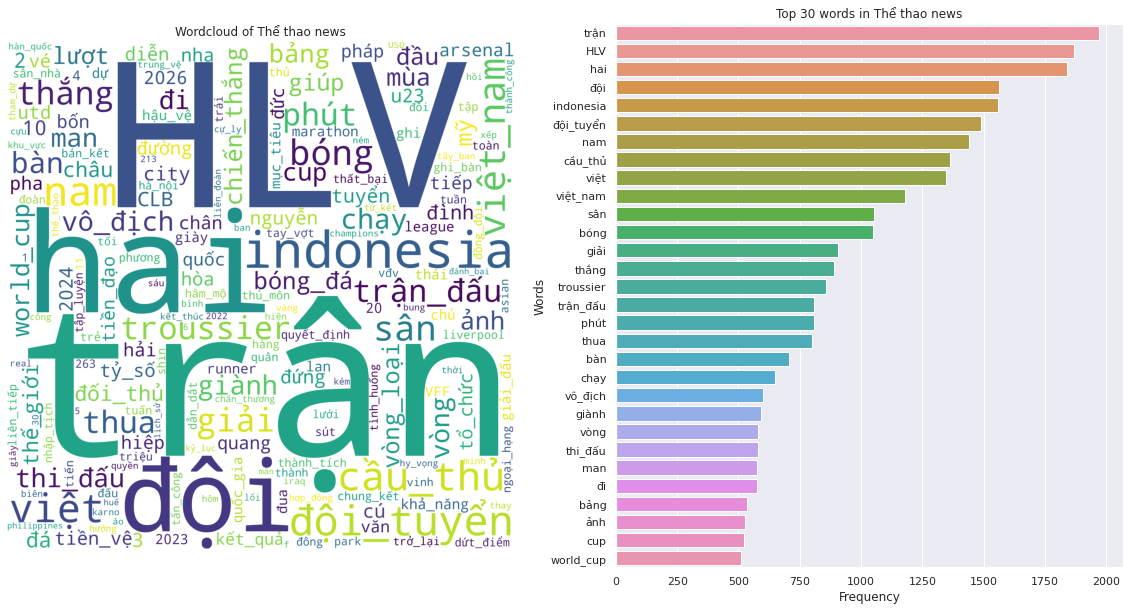

In [ ]:
draw_wordcloud_and_barplot(news, 'Thể thao', "content")

#### Đời sống
Từ biểu đồ ta có thể thấy chủ đề đời sống có các từ hoặc cụm từ phổ biến như: `ảnh`, `gia_đình`,...

Những từ hoặc cụm từ này có liên quan đến chủ đề `Đời sống`

Tuy nhiên, trong đó cũng tồn tại những từ không mang nhiều ý nghĩa cho chủ đề `Đời sống` như `đi`, `hai`,... Ngoài ra còn còn có các từ liên quan đến các chủ đề khác như `đồng`, `tiền` có ở `pháp luật`. `học` có ở `Giáo dục`.

[('ảnh', 1497), ('đi', 1364), ('hai', 1097), ('gia_đình', 1046), ('mẹ', 846), ('hàng', 761), ('tiền', 729), ('đầu', 673), ('sống', 660), ('trẻ', 637), ('đồng', 623), ('mua', 621), ('giúp', 611), ('phụ_nữ', 521), ('triệu', 508), ('việt', 491), ('hoa', 459), ('học', 456), ('chồng', 443), ('mạng', 436), ('đường', 434), ('tết', 430), ('vợ', 426), ('nam', 412), ('gái', 412), ('xã_hội', 404), ('bé', 398), ('vàng', 380), ('dân', 375), ('món', 371)]


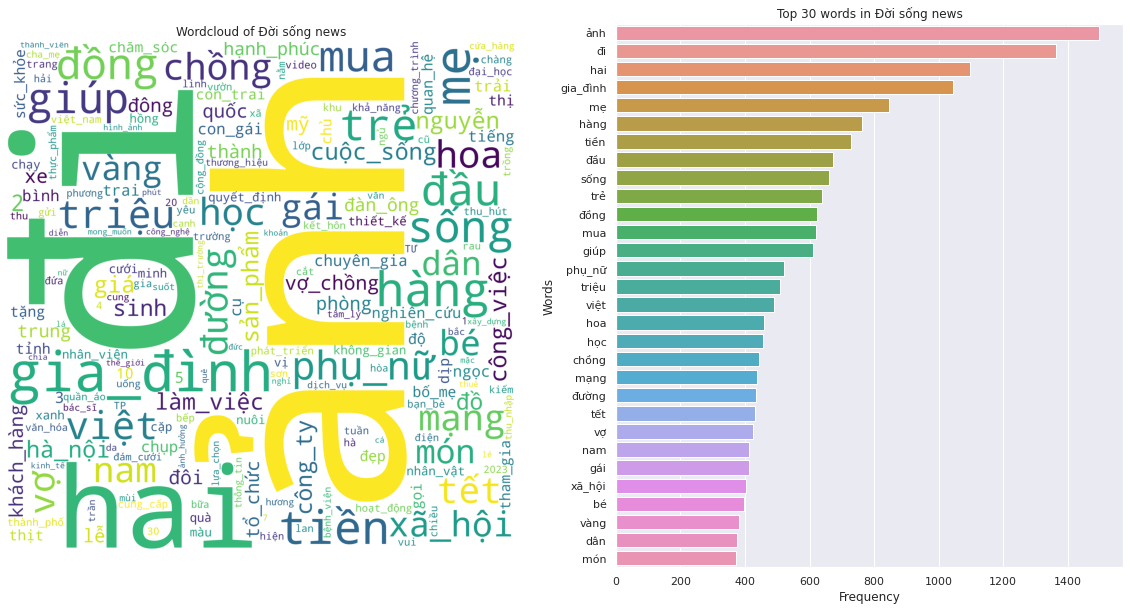

In [ ]:
draw_wordcloud_and_barplot(news, 'Đời sống', "content")

## 3.5. Trực quan hóa dữ nhiều biến

In [ ]:
def find_freq(word, word_freq):
    for w, freq in word_freq:
        if w == word:
            return freq
    return 0

In [ ]:
def words_frequency(data, category, column_name="content"):
    words_count = {}

    if category == "all":
        query_category = data[column_name].str.split().dropna().sum()
    else:
        query_category = data.query(f"category == '{category}'")[column_name].str.split().dropna().sum()
    for word in query_category:
        if word in words_count:
            words_count[word] += 1
        else:
            words_count[word] = 1

    return sorted(words_count.items(), key=lambda x: x[1], reverse=True)

In [ ]:
def words_frequency_dict(data, category, column_name="content"):
    words_freq = words_frequency(data, category, column_name)
    return [[word, word_count] for word, word_count in words_freq]

In [ ]:
def plot_heatmap(data, column_name="content"):
    """
        Hàm này dùng để vẽ biểu đồ heatmap của tần suất xuất hiện của các từ phổ biến nhất của một danh mục so với các danh mục khác
        data: DataFrame chứa dữ liệu
        column_name: Tên cột chứa nội dung cần xử lý

        Ví dụ: plot_heatmap(news, "content")
    """
    # An dict contain a dataframe of each categories, contain the count vectorized feature
    words_freq_dict = {
        "Du lịch": pd.DataFrame(words_frequency_dict(data, 'Du lịch', column_name), columns=["Word", "Frequency"]),
        "Giáo dục": pd.DataFrame(words_frequency_dict(data, 'Giáo dục', column_name), columns=["Word", "Frequency"]),
        "Giải trí": pd.DataFrame(words_frequency_dict(data, 'Giải trí', column_name), columns=["Word", "Frequency"]),
        "Pháp luật": pd.DataFrame(words_frequency_dict(data, 'Pháp luật', column_name), columns=["Word", "Frequency"]),
        "Sức khỏe": pd.DataFrame(words_frequency_dict(data, 'Sức khỏe', column_name), columns=["Word", "Frequency"]),
        "Thế giới": pd.DataFrame(words_frequency_dict(data, 'Thế giới', column_name), columns=["Word", "Frequency"]),
        "Thể thao": pd.DataFrame(words_frequency_dict(data, 'Thể thao', column_name), columns=["Word", "Frequency"]),
        "Đời sống": pd.DataFrame(words_frequency_dict(data, 'Đời sống', column_name), columns=["Word", "Frequency"])
    }

    categories = list(words_freq_dict.keys())

    # Set the 'word' column to index column
    for category, df in words_freq_dict.items():
        words_freq_dict[category] = df.set_index('Word')

    words_count_df_all_cates = pd.concat([words_freq_dict[category]["Frequency"].rename(category) for category in categories], axis=1)
    words_count_df_all_cates.fillna(0, inplace=True)
    words_count_df_all_cates.head()

    def heatmap_word_count(cat, ax=None):
        sorted_bydu_lich_df = words_count_df_all_cates.sort_values(cat, ascending=False)
        sns.heatmap(sorted_bydu_lich_df[:15], cmap='YlGnBu', ax=ax)

    fig, axs = plt.subplots(2, 4, figsize=(25,10))
    fig.suptitle(f'Tần suất của các từ phổ biến nhất của một danh mục so với các danh mục khác của cột [{column_name}]')
    plt.subplots_adjust(hspace = 0.4, wspace=0.4)
    for i in range(2):
        for j in range(4):
            cat = categories[i*4+j]
            heatmap_word_count(cat, axs[i][j])
            axs[i][j].set_title(f'{cat}')
            axs[i][j].set_xticks(axs[i][j].get_xticks(), axs[i][j].get_xticklabels(), rotation=45)

    plt.show()

In [ ]:
def plot_distribution(data, column_name="content"):
    """
        Hàm này dùng để vẽ biểu đồ phân phối của các từ phổ biến nhất trong các lĩnh vực
        Đầu vào:
            - data: dữ liệu cần vẽ
            - column_name: tên cột cần vẽ
        Đầu ra:
            - Biểu đồ phân phối của các từ phổ biến nhất trong các lĩnh vực

        Ví dụ: plot_distribution(news, "content")
    """
    words_freq = {
        "Du lịch": words_frequency(data, 'Du lịch', column_name),
        "Giáo dục": words_frequency(data, 'Giáo dục', column_name),
        "Giải trí": words_frequency(data, 'Giải trí', column_name),
        "Pháp luật": words_frequency(data, 'Pháp luật',column_name),
        "Sức khỏe": words_frequency(data, 'Sức khỏe', column_name),
        "Thế giới": words_frequency(data, 'Thế giới', column_name),
        "Thể thao": words_frequency(data, 'Thể thao', column_name),
        "Đời sống": words_frequency(data, 'Đời sống', column_name)
    }

    set_words_freq = {
        "Du lịch": set([x[0] for x in words_freq["Du lịch"]]),
        "Giáo dục": set([x[0] for x in words_freq["Giáo dục"]]),
        "Giải trí": set([x[0] for x in words_freq["Giải trí"]]),
        "Pháp luật": set([x[0] for x in words_freq["Pháp luật"]]),
        "Sức khỏe": set([x[0] for x in words_freq["Sức khỏe"]]),
        "Thế giới": set([x[0] for x in words_freq["Thế giới"]]),
        "Thể thao": set([x[0] for x in words_freq["Thể thao"]]),
        "Đời sống": set([x[0] for x in words_freq["Đời sống"]])
    }

    set_words = set_words_freq["Du lịch"].intersection(set_words_freq["Giáo dục"]).intersection(set_words_freq["Giải trí"]).intersection(set_words_freq["Pháp luật"]).intersection(set_words_freq["Sức khỏe"]).intersection(set_words_freq["Thế giới"]).intersection(set_words_freq["Thể thao"]).intersection(set_words_freq["Đời sống"])

    freq_intersection = []
    for word in set_words:
        freq_intersection.append(
            (word,
            find_freq(word, words_freq["Du lịch"]),
            find_freq(word, words_freq["Giáo dục"]),
            find_freq(word, words_freq["Giải trí"]),
            find_freq(word, words_freq["Pháp luật"]),
            find_freq(word, words_freq["Sức khỏe"]),
            find_freq(word, words_freq["Thế giới"]),
            find_freq(word, words_freq["Thể thao"]),
            find_freq(word, words_freq["Đời sống"])
            )
        )

    print(f"Biểu đồ biểu diễn sự xuất hiện của các từ chung trong các lĩnh vực ({column_name})")
    fig, axs = plt.subplots(2, 4, figsize=(15, 10))
    for i in range(2):
        for j in range(4):
            # axs[i, j].axis('off')
            freq_intersection.sort(key=lambda x: x[i*4 + j + 1], reverse=True)
            sns.barplot(y=[x[0] for x in freq_intersection[:10]], x=[x[1] for x in freq_intersection[:10]], ax=axs[i, j], label = "Du lịch", color="red", alpha=0.5)
            sns.barplot(y=[x[0] for x in freq_intersection[:10]], x=[x[2] for x in freq_intersection[:10]], ax=axs[i, j], label = "Giáo dục", color="blue", alpha=0.5)
            sns.barplot(y=[x[0] for x in freq_intersection[:10]], x=[x[3] for x in freq_intersection[:10]], ax=axs[i, j], label = "Giải trí", color="green", alpha=0.5)
            sns.barplot(y=[x[0] for x in freq_intersection[:10]], x=[x[4] for x in freq_intersection[:10]], ax=axs[i, j], label = "Pháp luật", color="yellow", alpha=0.5)
            sns.barplot(y=[x[0] for x in freq_intersection[:10]], x=[x[5] for x in freq_intersection[:10]], ax=axs[i, j], label = "Sức khỏe", color="purple", alpha=0.5)
            sns.barplot(y=[x[0] for x in freq_intersection[:10]], x=[x[6] for x in freq_intersection[:10]], ax=axs[i, j], label = "Thế giới", color="orange", alpha=0.5)
            sns.barplot(y=[x[0] for x in freq_intersection[:10]], x=[x[7] for x in freq_intersection[:10]], ax=axs[i, j], label = "Thể thao", color="brown", alpha=0.5)
            sns.barplot(y=[x[0] for x in freq_intersection[:10]], x=[x[8] for x in freq_intersection[:10]], ax=axs[i, j], label = "Đời sống", color="black", alpha=0.5)
            axs[i, j].set_xlabel("Frequency")
            axs[i, j].set_ylabel("Words")
            axs[i, j].set_title(f"Sắp xếp theo lĩnh vực {list(words_freq.keys())[i*4 + j]}")
            axs[i, j].legend()

    plt.tight_layout()
    plt.show()

### 3.5.1. Biểu diễn dữ liệu với 2 cột dữ liệu "title", "description" tới "Category"

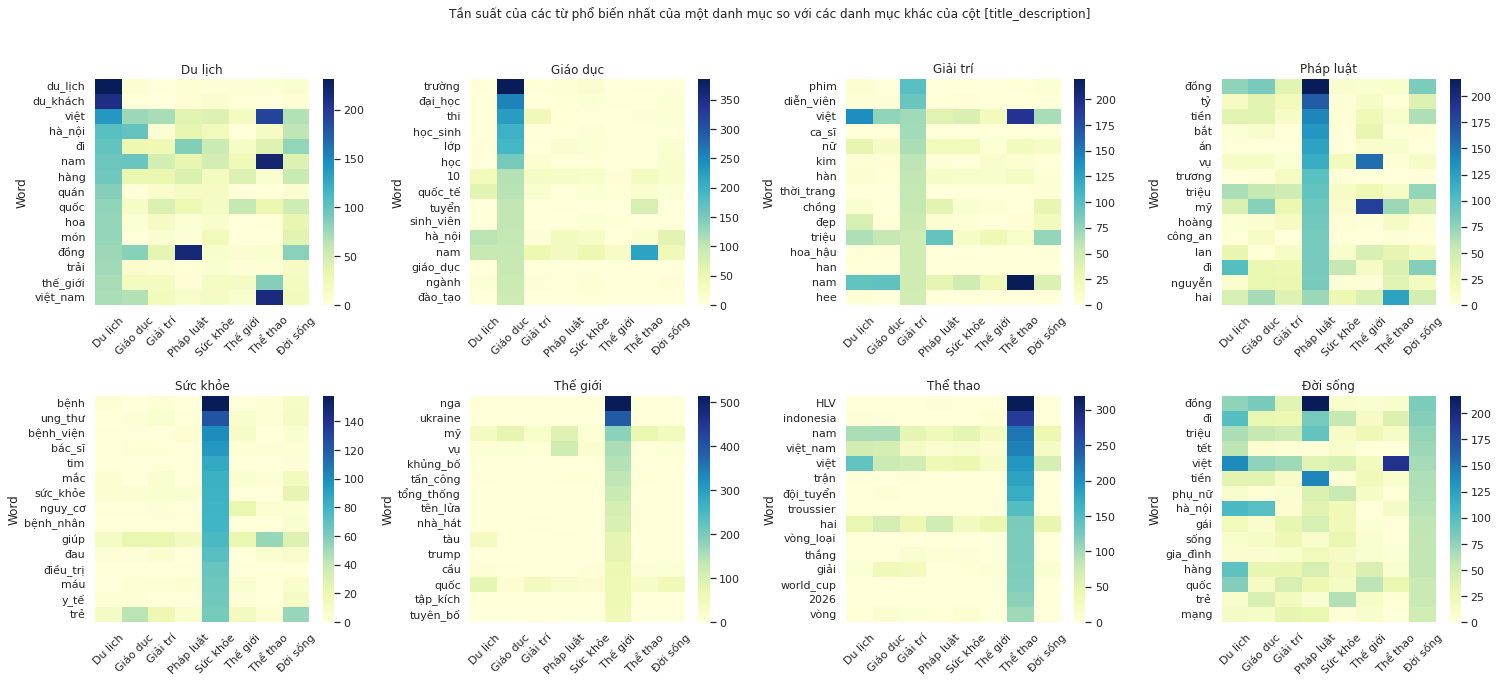

Biểu đồ biểu diễn sự xuất hiện của các từ chung trong các lĩnh vực (title_description)


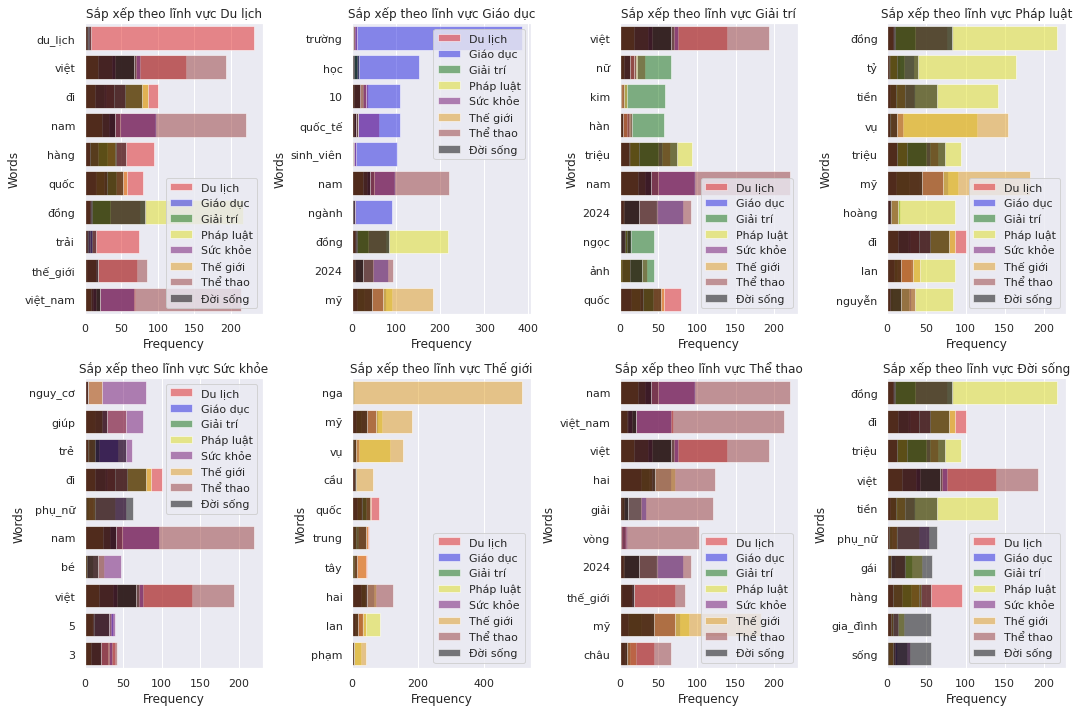

In [ ]:
news["title_description"] = news["title"] + " " + news["description"]
plot_heatmap(news, "title_description")
plot_distribution(news, "title_description")

Đối với đầu vào là `tiêu đề` (title) và `mô tả` (description):

Nhìn vào biểu đồ **Tần suất của các từ phổ biến của một danh mục so với các danh mục khác (bên trên)**, ta có thể nhận thấy các danh mục / chủ đề `Du lịch`, `Giáo dục`, `Sức khỏe`, `Thế giới`, `Pháp luật` và `Thể thao` là có sự đặc trưng rõ rệt có nhiều sự khác biệt. Tuy nhiên ở danh mục `Đời sống` và `Giải trí` lại xuất hiện tần suất xuất hiện tại những danh mục khác cao, điều này có thể khiến hai chủ đề này bị nhầm lẫn bởi các chủ đề khác.
    

Nhìn vào biểu đồ **Biểu đồ biểu diễn sự xuất hiện của các từ chung trong các lĩnh vực (bên dưới)** ta có thể tần suất xuất hiện các từ phổ biến ở các nhãn có sự khác biệt tuy nhiên không quá nhiều. Từ biểu đồ này ta có nhận thấy chủ đề `Giáo dục`, `Thế giới`, `Pháp luật` và `Thể thao` có thể phân loại và dự đoán. Tuy nhiên, các chủ đề **Du lịch, Sức khỏe, Đời sống, Giải trí** có thể bị ảnh hưởng và cho ra các dự đoán nhầm lẫn với các chủ đề khác (có thể xem các đặc trưng này là chưa rõ ràng)

Kết luận: Khi sử dụng thông tin đầu vào là sự kết hợp của hai cột `tiêu đề` và `mô tả` các danh mục:
 * có thể dự đoán mức cao là `Giáo dục`, `Thế giới`, `Pháp luật` và `Thể thao`.
 * có thể dự đoán mức trung là `Sức khỏe`, `Du lịch` (có các từ đặc biệt như `du_lich`, `du_khách`).
 * có mức dự đoán mức thấp (rất dễ bị nhầm lẫn): `Giải trí`, `Đời sống`.

### 3.5.2. Biểu diễn tính tương quan 1 cột dữ liệu "Nội dung - Content" đến "Chủ đề - Category"

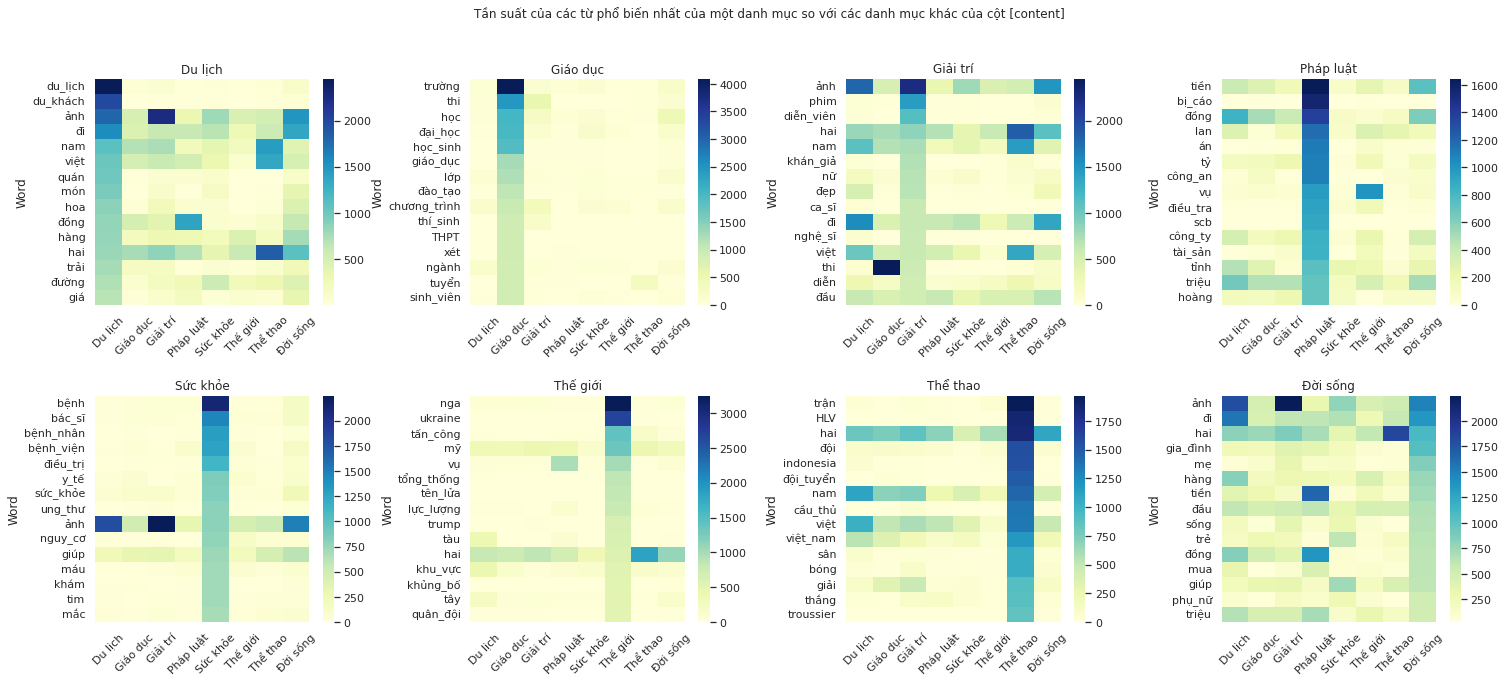

Biểu đồ biểu diễn sự xuất hiện của các từ chung trong các lĩnh vực (content)


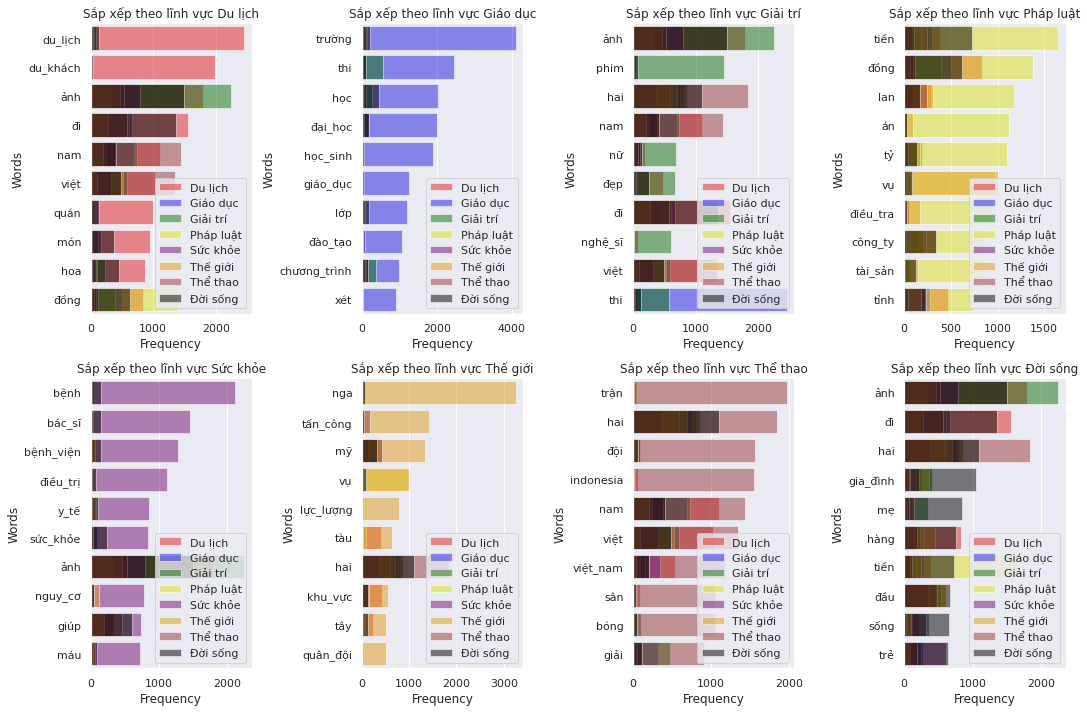

In [ ]:
plot_heatmap(news, "content")
plot_distribution(news, "content")

Khi biểu diễn mối quan hệ của cột `Nội dung` (content) với `Chủ đề` (Category):

Nhìn vào biểu đồ **Tần suất của các từ phổ biến của một danh mục so với các danh mục khác (bên trên)**, ta có thể nhận thấy các danh mục / chủ đề `Du lịch`, `Giáo dục`, `Sức khỏe`, `Thế giới`, `Pháp luật` và `Thể thao` là có sự đặc trưng rõ rệt có nhiều sự khác biệt. Tuy nhiên ở danh mục `Đời sống` và `Giải trí`, tuy đã có rõ ràng về lượng đặc trưng hơn so với biểu đồ `3.5.1` (sử dụng `tiêu đề` + `mô tả`) nhưng vẫn có các tần suất các từ xuất hiện ở các doanh mục khác khá là cao nên 2 doanh mục này có thể bị dự đoán nhầm thành các doanh mục khác. Mặc dù vậy nhưng danh mục `Giải trí` vẫn có các từ đặc biệt có tần suất xuất hiện ít trong các lĩnh vực khác như  `phim`, `diễn_viên`.
    

Nhìn vào biểu đồ **Biểu đồ biểu diễn sự xuất hiện của các từ chung trong các lĩnh vực (bên dưới)**, ta có thể nhận thấy các chủ đề như `Du lịch`, `Giáo dục`, `Sức khỏe`, `Thế giới`, `Pháp luật` và `Thể thao` với các từ xuất hiện chung trong các lĩnh vực thì đều cho thấy sự khác biệt rõ rệt về tần suất nên ta có thể nhận định rằng các chủ đề này có thể phân loại và dự đoán.

Kết luận: Khi sử dụng thông tin đầu vào là sự kết hợp của `Nội dung` các danh mục:
 * có thể dự đoán mức cao là `Giáo dục`, `Sức khỏe`, `Thế giới`, `Pháp luật` và `Thể thao`.
 * có thể dự đoán mức trung là `Du lịch` (Có các từ đặc biệt như `du_lịch`, `du_khách`), `Giải trí` (bởi doanh mục này vẫn có những từ đặc biệt như `phim`, `diễn_viên`)
 * có mức dự đoán mức thấp (rất dễ bị nhầm lẫn): `Đời sống`.

----
Nâng số nhãn có thể dự đoán mức chính xác cao lên 5.

### 3.5.3. Biểu diễn dữ liệu với 2 cột dữ liệu "Content", "title" tới "Category"

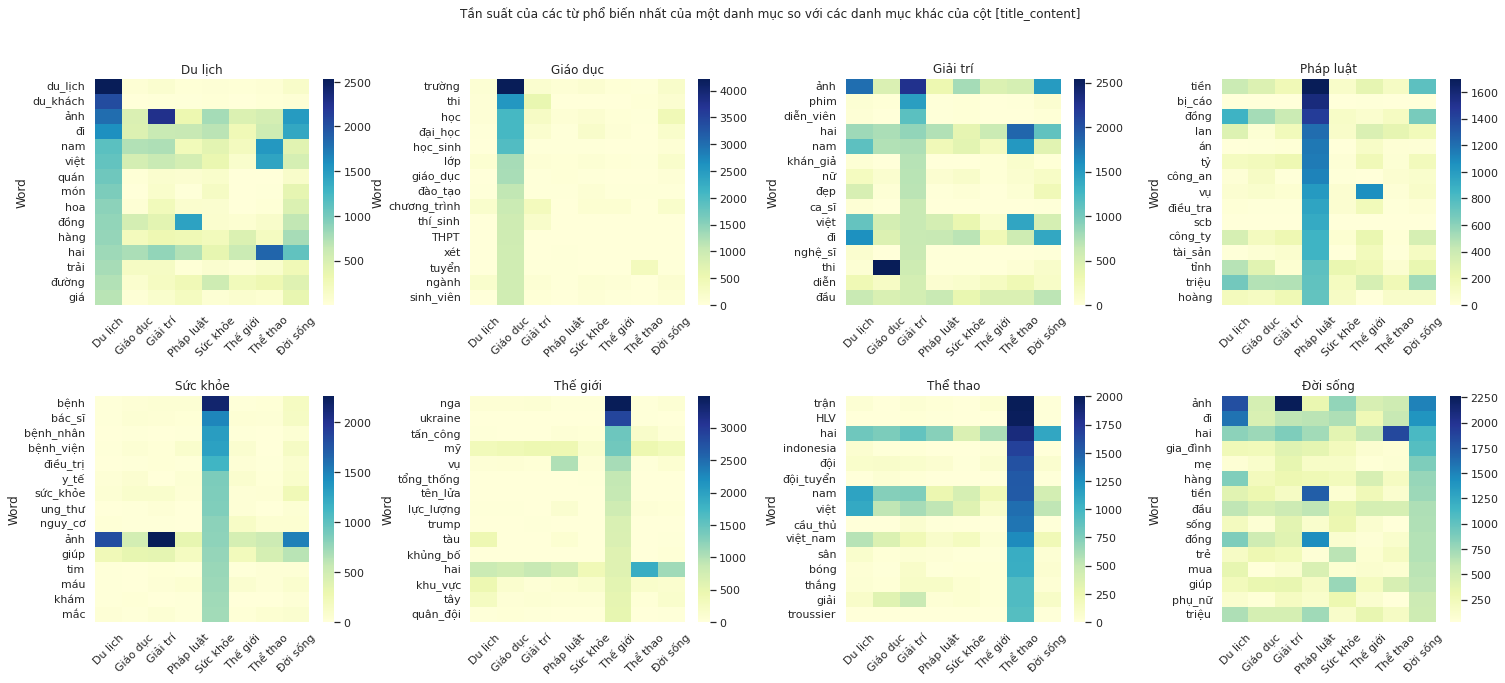

Biểu đồ biểu diễn sự xuất hiện của các từ chung trong các lĩnh vực (title_content)


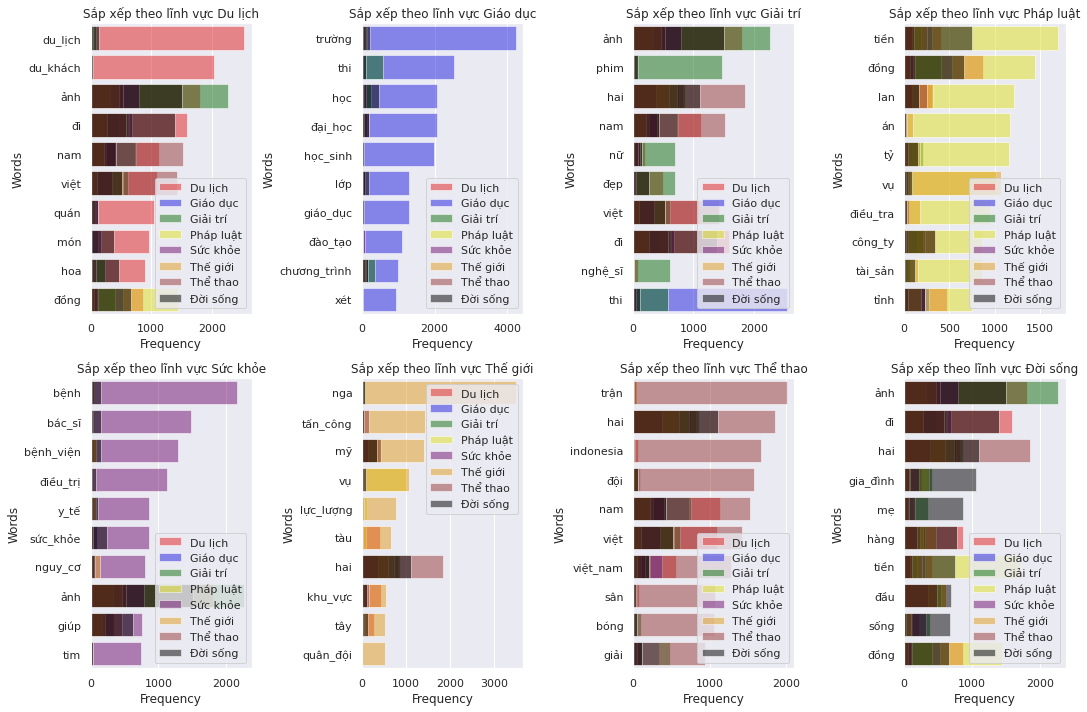

In [ ]:
news["title_content"] = news["title"] + " " + news["content"]
plot_heatmap(news, "title_content")
plot_distribution(news, "title_content")

Khi biểu diễn sự ảnh hưởng của 2 cột `Tiêu đề` (title) và `Nội dung` (content) tới `Chủ đề` (Category):

Nhìn vào biểu đồ **Tần suất của các từ phổ biến của một danh mục so với các danh mục khác (bên trên)**, ta có thể nhận thấy các danh mục / chủ đề `Du lịch`, `Giáo dục`, `Sức khỏe`, `Thế giới`, `Pháp luật` và `Thể thao` là có sự đặc trưng rõ rệt có nhiều sự khác biệt. Tuy nhiên ở danh mục `Đời sống` và `Giải trí`, không có sự khác biệt quá nhiều so với biểu đồ `3.5.2` (sử dụng `nội dung`), tần suất các từ xuất hiện ở các doanh mục khác khá là cao nên 2 doanh mục này có thể bị dự đoán nhầm thành các doanh mục khác. Mặc dù vậy nhưng danh mục `Giải trí` vẫn có các từ đặc biệt có tần suất xuất hiện ít trong các lĩnh vực khác như  `phim`, `diễn_viên`.


Nhìn vào biểu đồ **Biểu đồ biểu diễn sự xuất hiện của các từ chung trong các lĩnh vực (bên dưới)**, ta có thể nhận thấy các chủ đề như `Du lịch`, `Giáo dục`, `Sức khỏe`, `Thế giới`, `Pháp luật` và `Thể thao` với các từ xuất hiện chung trong các lĩnh vực thì đều cho thấy sự khác biệt rõ rệt về tần suất nên ta có thể nhận định rằng các chủ đề này có thể phân loại và dự đoán.

Kết luận: Khi sử dụng thông tin đầu vào là sự kết hợp của `Tiêu đề` (title) và `Nội dung` (content) có sự rõ ràng hơn so với chỉ sử dụng `Nội dung` ở các danh mục như `Thể thao` (như sự thay đổi của vị trí của từ `đội` với `indonesia`), danh mục `Sử khỏe`(sự thay đổi của top 10 từ là sự xuất hiện của từ `tim` thay vì `máu`) nhưng các thay đổi này có những không quá nhiều, điều này có thể khiến lượng thông tin đặc trưng tăng, ta có thể hi vọng rằng kết quả dự đoán có thể chính xác hơn. Về tổng kết thì ở sự kết hợp `Tiêu đề` (title) và `Nội dung` (content) ta có thể xác định các thông tin dự đoán dự kiến nhìn thấy từ dữ liệu như sau:
 * có thể dự đoán mức cao là `Giáo dục`, `Sức khỏe`, `Thế giới`, `Pháp luật` và `Thể thao`.
 * có thể dự đoán mức trung là `Du lịch` (Có các từ đặc biệt như `du_lịch`, `du_khách`), `Giải trí` (Có các từ đặc biệt như `phim`, `diễn_viên`).
 * có mức dự đoán mức thấp (rất dễ bị nhầm lẫn): `Đời sống`.

----
Số nhãn có thể dự đoán mức chính xác cao lên 5.

### 3.5.4. Biểu diễn dữ liệu với 3 cột dữ liệu "Content", "title", "description" tới "Category"

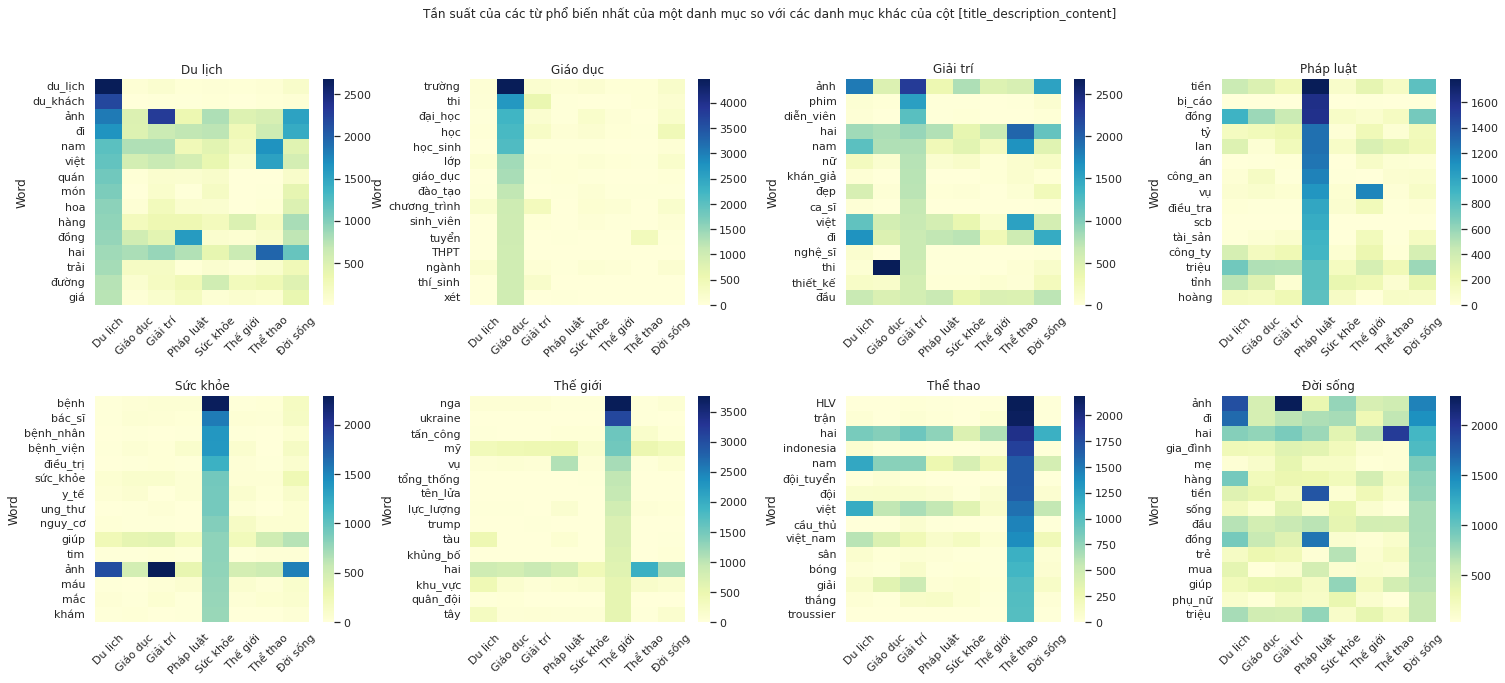

Biểu đồ biểu diễn sự xuất hiện của các từ chung trong các lĩnh vực (title_description_content)


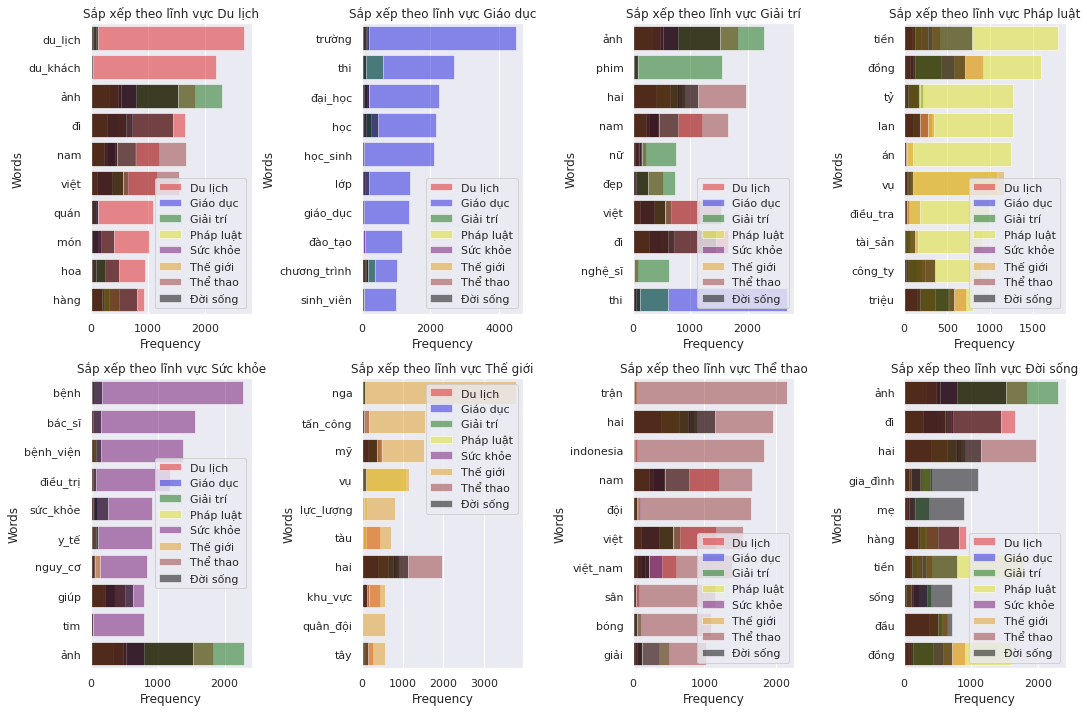

In [ ]:
news["title_description_content"] = news["title"] + " " + news["description"] + " " + news["content"]
plot_heatmap(news, "title_description_content")
plot_distribution(news, "title_description_content")

Khi biểu diễn sự ảnh hưởng của 3 cột `Tiêu đề` (title), `Mô tả` (description) và `Nội dung` (content) tới `Chủ đề` (Category):

Nhìn vào biểu đồ **Tần suất của các từ phổ biến của một danh mục so với các danh mục khác (bên trên)**, ta có thể nhận thấy các danh mục / chủ đề `Du lịch`, `Giáo dục`, `Sức khỏe`, `Thế giới`, `Pháp luật` và `Thể thao` là có sự đặc trưng rõ rệt có nhiều sự khác biệt. Tuy nhiên ở danh mục `Đời sống` và `Giải trí`, không có sự khác biệt quá nhiều so với biểu đồ `3.5.3` (sử dụng `Tiêu đề` + `nội dung`), tần suất các từ xuất hiện ở các doanh mục khác khá là cao nên 2 doanh mục này có thể bị dự đoán nhầm thành các doanh mục khác.


Nhìn vào biểu đồ **Biểu đồ biểu diễn sự xuất hiện của các từ chung trong các lĩnh vực (bên dưới)**, ta có thể nhận thấy các chủ đề như `Du lịch`, `Giáo dục`, `Sức khỏe`, `Thế giới`, `Pháp luật` và `Thể thao` với các từ xuất hiện chung trong các lĩnh vực thì đều cho thấy sự khác biệt rõ rệt về tần suất nên ta có thể nhận định rằng các chủ đề này có thể phân loại và dự đoán.

Kết luận: Khi sử dụng thông tin đầu vào là sự kết hợp của `Tiêu đề` (title), `Mô tả` (description) và `Nội dung` (content) có sự rõ ràng hơn so với chỉ sử dụng `Tiêu đề` + `nội dung`. Ví dụ như ở mục `Sức khỏe` ( từ `ảnh` xuống top 10 thay vì top 8 như biểu đồ sử dụng `Tiêu đề` + `nội dung`), mục `Pháp luật` (cụm từ `tài_sản` và `công_ty` có sự thay đổi về vị trí) điều này có thể hi vọng rằng sự kết hợp này có thể khiển việc khẳng định các nhãn mức dự đoán cao một cách rõ ràng hơn.
Về tổng kết thì ở sự kết hợp `Tiêu đề` (title) và `Nội dung` (content) ta có thể xác định các thông tin dự đoán dự kiến nhìn thấy từ dữ liệu như sau:
 * có thể dự đoán mức cao là `Giáo dục`, `Sức khỏe`, `Thế giới`, `Pháp luật` và `Thể thao`.
 * có thể dự đoán mức trung là `Du lịch` (Có các từ đặc biệt như `du_lịch`, `du_khách`), `Giải trí` (Có các từ đặc biệt như `phim`, `diễn_viên`).
 * có mức dự đoán mức thấp (rất dễ bị nhầm lẫn):  `Đời sống`.

----
Nhãn có thể dự đoán mức chính xác cao lên 5.

## 3.6. Kết luận phần trực quan dữ liệu

Việc phân loại bài báo có thể bị ảnh hưởng bởi nhiều yếu tố, tuy nhiên trong quá trình trực quan hóa dữ liệu và đánh giá thì nhóm có thể xác định các features (đặc trưng) cho bài toán phân loại chủ đề của bái báo.


$F(X) = Y$


Với **X** là các đặc trưng được sử dụng như là: `title` (tiêu đề), `description` (Mô tả) và `content` (Nội dung).

Với **Y** là chủ đề dự đoán của bài báo (target là chủ đề bài báo)

----
Tuy nhiên, ta có thể nhận xét rằng chủ đề `Đời sống` có thể bị nhầm lẫn với các chủ đề khác.
